# Tatoeba all-token error subspaces → KLAR oracle projection: GPTQ, AWQ, BNB and random controls

Each quantization method gets its **own** FP16-minus-quantized Tatoeba error matrix, SVD basis, saved 500-fact discordance selection, and recovery run. Both random controls use the same independently seeded, rank-matched orthonormal subspace and project the **same current per-token FP16−quantized error**. The second control additionally rescales each token's random projection to match the norm of its SVD projection. Thus one comparison matches subspace dimension, while the other matches both dimension and correction strength. All interventions remain FP16 oracles, not deployable corrections.

Accuracy summaries first remain per language. At the end, counts are recomputed from sample-level rows pooled across all target languages for each method, with the two historical discordance directions shown separately and together. These are **selection-conditioned accuracies**, not accuracy on the full 500 × 12 evaluation set. No FP16 baseline is regenerated. Quantized baselines are rerun on selected cases and historical status consistency is reported.


**Method references and attribution.** The discovery corpus is the OPUS/Tatoeba parallel corpus (fixed release `v2021-07-22`; see [Tiedemann, 2012](https://aclanthology.org/L12-1246/) for OPUS). The language-specific SVD error bases, per-token projection, discordance-cohort selection, and random/norm-matched controls are this project's experimental design; they should not be described as methods proposed by the OPUS paper.


In [2]:
import gc, json, math, os, random, urllib.parse, urllib.request, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_DATASETS_CACHE', '/root/autodl-tmp/huggingface/datasets')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

torch.set_grad_enabled(False)

# Faster matrix multiplication for the very large score GEMMs on Ampere+ GPUs.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')

## 1. Configuration

`RECOVERY_ENERGY_THRESHOLDS` are fractions of the **raw Tatoeba all-token error energy**. The first principal direction is not assumed sufficient; each language uses the smallest rank reaching each threshold. `MAX_SVD_RANK` must be large enough to reach 70% for all languages. KLAR generation runs FP16 and BNB-NF4 simultaneously so that each current-prefix token has its own paired error. Results use a new oracle-specific filename and are saved after each batch for safe resumption.

In [3]:
FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_METHODS = ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']
QUANT_MODEL_NAME = None
RANDOM_CONTROL_REPEATS = 1  # Increase to >=3 for a stronger random baseline.

TATOEBA_VERSION = 'v2021-07-22'
OPUS_API = 'https://opus.nlpl.eu/opusapi/'
TATOEBA_DATA_DIR = Path('/root/autodl-tmp/data/tatoeba_opus')
TATOEBA_LANG_CODES = {
    'ca': 'ca', 'es': 'es', 'fr': 'fr', 'hu': 'hu', 'nl': 'nl', 'tr': 'tr',
    'ar': 'ar', 'el': 'el', 'he': 'he', 'ja': 'ja', 'ko': 'ko', 'zh': 'cmn',
}

LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
LANGUAGE_SCRIPT_GROUPS = {
    'ca': 'Latin', 'en': 'Latin', 'es': 'Latin', 'fr': 'Latin',
    'hu': 'Latin', 'nl': 'Latin', 'tr': 'Latin',
    'ar': 'Non-Latin', 'el': 'Non-Latin', 'he': 'Non-Latin',
    'ja': 'Non-Latin', 'ko': 'Non-Latin', 'zh': 'Non-Latin',
}
SCRIPT_GROUP_ORDER = ['Latin', 'Non-Latin']

SEED = 2026
DTYPE = torch.float16
DEVICE_MAP = 'auto'
FORCE_SINGLE_GPU_MODELS = False
USE_KV_CACHE = True
TRUST_REMOTE_CODE = True
MAX_LENGTH = 512
BATCH_SIZE = 8

RECOVERY_LAYER = 7
TATOEBA_DISCOVERY_SAMPLES = 1000
ANALYSIS_RANKS = [1, 2, 4, 8, 16, 32, 64, 128]
INITIAL_SVD_RANK = 128
MAX_SVD_RANK = 1536
RECOVERY_ENERGY_THRESHOLDS = [0.50, 0.60, 0.70]
if (not RECOVERY_ENERGY_THRESHOLDS
        or any(not 0 < float(value) < 1 for value in RECOVERY_ENERGY_THRESHOLDS)
        or len(set(RECOVERY_ENERGY_THRESHOLDS)) != len(RECOVERY_ENERGY_THRESHOLDS)):
    raise ValueError('Energy thresholds must be distinct fractions in (0, 1).')
if not max(ANALYSIS_RANKS) <= INITIAL_SVD_RANK <= MAX_SVD_RANK:
    raise ValueError('Require max(ANALYSIS_RANKS) <= INITIAL_SVD_RANK <= MAX_SVD_RANK.')
SUBSPACE_DIMS = sorted(set(ANALYSIS_RANKS))
SVD_NITER = 4
PATCH_BETAS = [1.0]  # Keep intervention strength fixed during the energy sweep.
PATCH_CONDITIONS_PER_BATCH = 4
KLAR_BATCH_SIZE = 2
KLAR_MAX_LENGTH = 1024
KLAR_GENERATION_MAX_NEW_TOKENS = 8
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True
RECOMPUTE_TATOEBA_ERRORS = False  # A missing all-content-token cache is computed automatically.
RECOMPUTE_KLAR_RECOVERY = False

# Variables expected by the reused Tatoeba loader.
PAPER_DISCOVERY_SAMPLES = TATOEBA_DISCOVERY_SAMPLES
CENTROID_SAMPLES = PAPER_DISCOVERY_SAMPLES
RECOVERY_SAMPLES = 0

DATASET_TAG = f'tatoeba_{TATOEBA_DISCOVERY_SAMPLES}_12targets'
BASE_ANALYSIS_DIR = Path(
    '/root/autodl-tmp/analysis/'
    'type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/'
    'content_masked_mean_tokens'
)
OUTPUT_DIR = BASE_ANALYSIS_DIR / 'tatoeba_common_error_subspace_all_content_tokens_klar'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Select all saved FP16-correct / BNB-NF4-wrong cases from the aligned 500-fact run.
KLAR_500_FP_DIR = Path(
    '/root/autodl-tmp/analysis/klar_gptq_english_500facts_template0_12languages_top1_fp16'
)
KLAR_500_QUANT_DIRS = {
    'GPTQ-INT4': Path('/root/autodl-tmp/analysis/klar_gptq_english_500facts_template0_12languages_top1_fp16'),
    'AWQ-INT4': Path('/root/autodl-tmp/analysis/klar_awq_all_aligned_facts_template0_12languages_top1_fp16'),
    'BNB-NF4': Path('/root/autodl-tmp/analysis/klar_bnb_english_500facts_template0_12languages_top1_fp16'),
}
QUANT_CHECKPOINTS = {
    'GPTQ-INT4': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4'),
    'AWQ-INT4': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4'),
}
KLAR_500_MANIFEST = KLAR_500_FP_DIR / 'sampled_english_500_question_ids.csv'

KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('Output:', OUTPUT_DIR)
print('Discovery: Tatoeba only')
print('Evaluation: method-specific discordant cases from the aligned 500 facts')
print('Quantized models:', QUANT_METHODS)
print('Recovery layer:', RECOVERY_LAYER)

Output: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/tatoeba_common_error_subspace_all_content_tokens_klar
Discovery: Tatoeba only
Evaluation: method-specific discordant cases from the aligned 500 facts
Quantized models: ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']
Recovery layer: 7


## 1. Independent Tatoeba discovery set

The target-language side of the fixed OPUS/Tatoeba release is used for subspace discovery. KLAR examples and correctness labels are not accessed here.


In [4]:
try:
    from opencc import OpenCC
except ImportError as exc:
    raise ImportError(
        'Simplified-Chinese normalization requires opencc-python-reimplemented. '
        'Install it with: pip install opencc-python-reimplemented'
    ) from exc

T2S_CONVERTER = OpenCC('t2s')


def normalize_target_text(language, text):
    """Normalize target text before deduplication and sampling."""
    text = text.strip()
    if language == 'zh':
        text = T2S_CONVERTER.convert(text)
    return text


def _opus_tatoeba_download(language):
    """Resolve and cache the fixed OPUS/Tatoeba Moses archive."""
    target_code = TATOEBA_LANG_CODES[language]
    TATOEBA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive_path = TATOEBA_DATA_DIR / f'Tatoeba_{TATOEBA_VERSION}_en-{target_code}.zip'

    params = urllib.parse.urlencode({
        'corpus': 'Tatoeba',
        'source': 'en',
        'target': target_code,
        'preprocessing': 'moses',
        'version': TATOEBA_VERSION,
    })
    api_url = f'{OPUS_API}?{params}'
    try:
        with urllib.request.urlopen(api_url, timeout=60) as response:
            payload = json.load(response)
    except Exception as exc:
        raise RuntimeError(
            f'Cannot query the official OPUS API for en-{target_code}: {api_url}. '
            f'{type(exc).__name__}: {exc}'
        ) from exc

    entries = payload.get('corpora', [])
    if not entries:
        raise RuntimeError(
            f'OPUS returned no Tatoeba {TATOEBA_VERSION} Moses archive for en-{target_code}.'
        )
    entry = entries[0]
    download_url = entry['url']

    if not archive_path.is_file() or archive_path.stat().st_size == 0:
        print(f'Downloading Tatoeba {TATOEBA_VERSION} en-{target_code}:', download_url)
        temporary_path = archive_path.with_suffix('.zip.part')
        try:
            urllib.request.urlretrieve(download_url, temporary_path)
            temporary_path.replace(archive_path)
        except Exception as exc:
            if temporary_path.exists():
                temporary_path.unlink()
            raise RuntimeError(
                f'Cannot download {download_url}. {type(exc).__name__}: {exc}'
            ) from exc

    return archive_path, entry, target_code


def _member_for_language(names, language_code):
    candidates = [
        name for name in names
        if not name.endswith('/')
        and Path(name).name.startswith('Tatoeba.')
        and Path(name).name.endswith(f'.{language_code}')
    ]
    if len(candidates) != 1:
        raise RuntimeError(
            f'Expected exactly one Tatoeba *.{language_code} file, found {candidates}.'
        )
    return candidates[0]


def _read_opus_moses_pairs(archive_path, target_code):
    with zipfile.ZipFile(archive_path) as archive:
        names = archive.namelist()
        english_member = _member_for_language(names, 'en')
        target_member = _member_for_language(names, target_code)
        english_lines = archive.read(english_member).decode('utf-8').splitlines()
        target_lines = archive.read(target_member).decode('utf-8').splitlines()

    if len(english_lines) != len(target_lines):
        raise RuntimeError(
            f'Unaligned Moses files in {archive_path}: '
            f'{len(english_lines)} English vs {len(target_lines)} target lines.'
        )
    return list(zip(english_lines, target_lines))


def load_tatoeba_pairs(language, required, seed):
    archive_path, entry, target_code = _opus_tatoeba_download(language)
    raw_pairs = _read_opus_moses_pairs(archive_path, target_code)
    rng = random.Random(seed)
    rng.shuffle(raw_pairs)

    pairs = []
    seen = set()
    for english, target in raw_pairs:
        english = english.strip()
        target = normalize_target_text(language, target)
        identity = (english, target)
        if not english or not target or identity in seen:
            continue
        seen.add(identity)
        pairs.append(identity)
        if len(pairs) >= required:
            break

    if len(pairs) < required:
        raise ValueError(
            f'Tatoeba en-{target_code} has only {len(pairs)} usable unique pairs; '
            f'{required} are required.'
        )
    return pairs, len(raw_pairs), target_code, entry['url']


CENTROID_KEYS = [f'train:{i}' for i in range(CENTROID_SAMPLES)]
# The paper's mono-train detection sentences are the target side of parallel-train.
DETECTION_KEYS = list(CENTROID_KEYS)
RECOVERY_KEYS = [f'test:{i}' for i in range(RECOVERY_SAMPLES)]

RECORDS = {language: {} for language in TARGET_LANGUAGES}
ENGLISH_RECORDS = {language: {} for language in TARGET_LANGUAGES}
TATOEBA_MANIFEST = {}

required = PAPER_DISCOVERY_SAMPLES + RECOVERY_SAMPLES
for language_index, language in enumerate(TARGET_LANGUAGES):
    pairs, corpus_size, target_code, download_url = load_tatoeba_pairs(
        language,
        required=required,
        seed=SEED + 1000 * (language_index + 1),
    )
    train_pairs = pairs[:PAPER_DISCOVERY_SAMPLES]
    recovery_pairs = pairs[PAPER_DISCOVERY_SAMPLES:]

    for key, (english, target) in zip(CENTROID_KEYS, train_pairs):
        ENGLISH_RECORDS[language][key] = {'prompt': english}
        RECORDS[language][key] = {'prompt': target}
    for key, (english, target) in zip(RECOVERY_KEYS, recovery_pairs):
        # Alignment analysis needs both sides of every held-out parallel pair.
        ENGLISH_RECORDS[language][key] = {'prompt': english}
        RECORDS[language][key] = {'prompt': target}

    TATOEBA_MANIFEST[language] = {
        'opus_target_code': target_code,
        'tatoeba_version': TATOEBA_VERSION,
        'corpus_rows': corpus_size,
        'parallel_centroid_pairs': len(train_pairs),
        'monolingual_detection_sentences': len(train_pairs),
        'held_out_recovery_sentences': len(recovery_pairs),
        'centroid_detection_share_target_side': True,
        'target_normalization': (
            'traditional_to_simplified' if language == 'zh' else 'none'
        ),
        'download_url': download_url,
    }


# Fail here with a clear message instead of much later inside alignment analysis.
for language in TARGET_LANGUAGES:
    missing_target = [key for key in RECOVERY_KEYS if key not in RECORDS[language]]
    missing_english = [key for key in RECOVERY_KEYS if key not in ENGLISH_RECORDS[language]]
    if missing_target or missing_english:
        raise RuntimeError(
            f'Incomplete recovery pairs for {language}: '
            f'missing target={missing_target[:3]}, missing English={missing_english[:3]}'
        )


def prompts(language, keys):
    return [RECORDS[language][key]['prompt'] for key in keys]


def english_prompts_for(language, keys):
    return [ENGLISH_RECORDS[language][key]['prompt'] for key in keys]


manifest_path = OUTPUT_DIR / 'tatoeba_dataset_manifest.json'
manifest_path.write_text(
    json.dumps(TATOEBA_MANIFEST, ensure_ascii=False, indent=2),
    encoding='utf-8',
)

display(pd.DataFrame(TATOEBA_MANIFEST).T)
for language in TARGET_LANGUAGES:
    print(
        language,
        '| train pair:', english_prompts_for(language, CENTROID_KEYS[:1])[0],
        '|||', prompts(language, DETECTION_KEYS[:1])[0],
    )
    if RECOVERY_KEYS:
        print(language, '| held-out recovery:', prompts(language, RECOVERY_KEYS[:1])[0])


KeyboardInterrupt



## 2. Model and hidden-state utilities

In [ ]:
def decoder_layers(model):
    for path in ('model.layers', 'model.decoder.layers', 'transformer.h', 'gpt_neox.layers'):
        obj = model
        ok = True
        for part in path.split('.'):
            if not hasattr(obj, part):
                ok = False
                break
            obj = getattr(obj, part)
        if ok:
            return obj
    raise AttributeError('Decoder layers not found.')


def input_device(model):
    return model.get_input_embeddings().weight.device


def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(
        FP16_CHECKPOINT, trust_remote_code=TRUST_REMOTE_CODE
    )
    tokenizer.padding_side = 'left'  # Batched generation reads logits[:, -1] from a valid token.
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer


def model_device_map(name):
    if torch.cuda.is_available() and torch.cuda.device_count() >= 2:
        # Keep both models fully on GPU and avoid auto CPU offload.
        return {'': 1 if name == 'FP16' else 0}
    if torch.cuda.is_available() and (FORCE_SINGLE_GPU_MODELS or name in QUANT_CHECKPOINTS):
        # Enable only when one GPU has enough VRAM for FP16 + BNB-NF4.
        return {'': 0}
    return DEVICE_MAP


def load_model(name):
    if name == 'FP16':
        kwargs = {'torch_dtype': DTYPE}
    elif name == 'BNB-NF4':
        kwargs = {
            'quantization_config': BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=DTYPE,
            )
        }
    elif name in QUANT_CHECKPOINTS:
        checkpoint = QUANT_CHECKPOINTS[name]
        if not checkpoint.is_dir():
            raise FileNotFoundError(checkpoint)
        if not torch.cuda.is_available():
            raise RuntimeError(f'{name} requires a CUDA GPU; AWQ cannot use CPU/disk offload.')
        kwargs = {'torch_dtype': DTYPE}
    else:
        raise KeyError(name)
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint if name in QUANT_CHECKPOINTS else FP16_CHECKPOINT,
        device_map=model_device_map(name),
        low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE,
        **kwargs,
    ).eval()
    model.config.use_cache = USE_KV_CACHE
    placement = getattr(model, 'hf_device_map', None)
    print(f'{name} placement:', placement if placement is not None else input_device(model))
    return model


def release_models(*models):
    for model in models:
        if model is not None:
            del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def encode_batch(tokenizer, texts, device, max_length=MAX_LENGTH):
    batch = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=max_length,
        add_special_tokens=True,
    )
    return {key: value.to(device) for key, value in batch.items()}


def content_token_mask(batch, require_nonempty=True):
    """Exclude padding and tokenizer special IDs; keep ordinary punctuation."""
    mask = batch['attention_mask'].bool()
    input_ids = batch['input_ids']
    for special_id in TOKENIZER.all_special_ids:
        mask = mask & input_ids.ne(int(special_id))
    if require_nonempty and (~mask.any(dim=1)).any():
        raise ValueError('At least one sequence has no content tokens.')
    return mask


@torch.no_grad()
def collect_all_content_token_layer_output(
    model, texts, layer_index, batch_size=BATCH_SIZE
):
    """Return token states, aligned token IDs, and row counts per sentence."""
    outputs, token_ids, sentence_counts = [], [], []
    layer = decoder_layers(model)[layer_index]
    for start in tqdm(
        range(0, len(texts), batch_size),
        desc=f'Layer {layer_index} all-content-token states', leave=False,
    ):
        batch = encode_batch(
            TOKENIZER, texts[start:start + batch_size], input_device(model)
        )
        mask = content_token_mask(batch)
        captured = {}

        def hook(_module, _inputs, output):
            captured['hidden'] = output[0] if isinstance(output, tuple) else output

        handle = layer.register_forward_hook(hook)
        try:
            model(
                **batch, output_hidden_states=False,
                use_cache=False, return_dict=True,
            )
        finally:
            handle.remove()
        if 'hidden' not in captured:
            raise RuntimeError(f'Layer {layer_index} hook captured no output.')
        selected = captured['hidden'][mask.to(captured['hidden'].device)]
        outputs.append(selected.detach().float().cpu())
        token_ids.append(batch['input_ids'][mask].detach().cpu())
        sentence_counts.append(mask.sum(dim=1).detach().cpu())
        del batch, captured, mask, selected
    return (
        torch.cat(outputs, dim=0),
        torch.cat(token_ids, dim=0),
        torch.cat(sentence_counts, dim=0),
    )


TOKENIZER = load_tokenizer()
print('Tokenizer loaded:', FP16_CHECKPOINT)
# Sanity check the exact mask used in discovery and recovery.
_mask_probe = encode_batch(
    TOKENIZER, ['Short.', 'A much longer sentence with several words.'],
    torch.device('cpu'),
)
_valid_probe = content_token_mask(_mask_probe)
assert bool((_mask_probe['attention_mask'] == 0).any()), 'Probe must contain padding.'
assert not bool((_valid_probe & (_mask_probe['attention_mask'] == 0)).any())
for _special_id in TOKENIZER.all_special_ids:
    assert not bool((_valid_probe & (_mask_probe['input_ids'] == _special_id)).any())
print('Mask check passed: padding and special IDs excluded.')


## Independent method-specific Tatoeba discovery and KLAR recovery

### GPTQ-INT4

All caches and results below are scoped to this method.

In [ ]:
QUANT_MODEL_NAME = 'GPTQ-INT4'
KLAR_500_QUANT_DIR = KLAR_500_QUANT_DIRS[QUANT_MODEL_NAME]
METHOD_DIR = OUTPUT_DIR / 'gptq_int4'
METHOD_DIR.mkdir(parents=True, exist_ok=True)
print('Method:', QUANT_MODEL_NAME, 'output:', METHOD_DIR)


## 3. Learn Layer-7 block-output error subspaces from all content tokens

For every target-language Tatoeba sentence $s$ and valid content-token position $t$, collect

$$e_{\lambda,s,t}=h^{FP}_{7,\lambda,s,t}-h^Q_{7,\lambda,s,t}.$$

The raw error matrix $E_{\lambda}$ stacks these $e_{\lambda,s,t}$ in sentence/token order. Padding and special tokens never enter it; FP16 and quantized token IDs and valid-token counts must align exactly. SVD uses the raw rows without sentence pooling, centering, or length weighting. Reported explained energy therefore refers to the raw all-token matrix. Longer sentences contribute more rows.


In [ ]:
TATOEBA_ERROR_CACHE = METHOD_DIR / (
    f'tatoeba_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_{TATOEBA_DISCOVERY_SAMPLES}_all_content_token_errors.pt'
)
TOKEN_CONVENTION = 'all non-padding, non-special tokens; punctuation retained'

if TATOEBA_ERROR_CACHE.exists() and not RECOMPUTE_TATOEBA_ERRORS:
    error_payload = torch.load(TATOEBA_ERROR_CACHE, map_location='cpu')
    if error_payload['languages'] != TARGET_LANGUAGES:
        raise RuntimeError('Tatoeba error cache has a different language list.')
    if error_payload.get('pooling') != TOKEN_CONVENTION:
        raise RuntimeError('Tatoeba cache uses a different token convention.')
    TATOEBA_ERRORS = error_payload['errors']
    TATOEBA_TOKEN_COUNTS = error_payload['token_counts']
    print('Loaded:', TATOEBA_ERROR_CACHE)
else:
    q_model = load_model(QUANT_MODEL_NAME)
    quant_states, quant_ids, quant_sentence_counts = {}, {}, {}
    for language in TARGET_LANGUAGES:
        (
            quant_states[language],
            quant_ids[language],
            quant_sentence_counts[language],
        ) = collect_all_content_token_layer_output(
            q_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
        )
    del q_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    fp_model = load_model('FP16')
    TATOEBA_ERRORS, TATOEBA_TOKEN_COUNTS = {}, {}
    for language in TARGET_LANGUAGES:
        fp_states, fp_ids, fp_sentence_counts = (
            collect_all_content_token_layer_output(
                fp_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
            )
        )
        if not torch.equal(fp_ids, quant_ids[language]):
            raise RuntimeError(f'{language}: FP16 and quantized token IDs differ.')
        if not torch.equal(fp_sentence_counts, quant_sentence_counts[language]):
            raise RuntimeError(f'{language}: FP16 and quantized sentence token counts differ.')
        if fp_states.shape != quant_states[language].shape:
            raise RuntimeError(f'{language}: FP16 and quantized state shapes differ.')
        TATOEBA_ERRORS[language] = fp_states - quant_states.pop(language)
        TATOEBA_TOKEN_COUNTS[language] = int(fp_states.shape[0])
        del fp_states, fp_ids, fp_sentence_counts
        del quant_ids[language], quant_sentence_counts[language]
    del fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    torch.save({
        'errors': TATOEBA_ERRORS,
        'languages': TARGET_LANGUAGES,
        'layer': RECOVERY_LAYER,
        'samples_per_language': TATOEBA_DISCOVERY_SAMPLES,
        'token_counts': TATOEBA_TOKEN_COUNTS,
        'pooling': TOKEN_CONVENTION,
        'definition': 'paired FP16 minus quantized block output, each content token',
    }, TATOEBA_ERROR_CACHE)
    print('Saved:', TATOEBA_ERROR_CACHE)

display(pd.DataFrame([
    {'language': language, 'sentences': TATOEBA_DISCOVERY_SAMPLES,
     'matrix_rows': TATOEBA_TOKEN_COUNTS[language],
     'mean_content_tokens_per_sentence':
         TATOEBA_TOKEN_COUNTS[language] / TATOEBA_DISCOVERY_SAMPLES}
    for language in TARGET_LANGUAGES
]))


DISCOVERY_ERRORS = TATOEBA_ERRORS
MAX_SUBSPACE_DIM = max(SUBSPACE_DIMS)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
LANGUAGE_BASES_MAX = {}
LANGUAGE_SINGULAR_VALUES = {}
svd_rows = []
energy_threshold_rows = []

for language in TARGET_LANGUAGES:
    errors = TATOEBA_ERRORS[language].to(
        device=SVD_DEVICE, dtype=torch.float32
    )
    max_feasible_rank = min(MAX_SVD_RANK, *errors.shape)
    if INITIAL_SVD_RANK > max_feasible_rank:
        raise ValueError(f'{language}: initial SVD rank exceeds matrix dimensions.')
    total_energy = errors.square().sum().cpu().clamp_min(1e-12)
    svd_rank = INITIAL_SVD_RANK
    while True:
        # Increase q only if the current approximation misses the largest target.
        _, singular_values_gpu, right_vectors = torch.pca_lowrank(
            errors, q=svd_rank, center=False, niter=SVD_NITER
        )
        singular_values = singular_values_gpu.cpu()
        cumulative_energy = singular_values.square().cumsum(0) / total_energy
        print(language, 'SVD rank', svd_rank,
              'energy covered', f'{float(cumulative_energy[-1]):.1%}')
        if float(cumulative_energy[-1]) >= max(RECOVERY_ENERGY_THRESHOLDS):
            break
        if svd_rank >= max_feasible_rank:
            raise ValueError(
                f'{language}: {max_feasible_rank} SVD directions cover only '
                f'{float(cumulative_energy[-1]):.1%}; requested '
                f'{max(RECOVERY_ENERGY_THRESHOLDS):.0%}. Increase MAX_SVD_RANK '
                'if memory/time permits.'
            )
        del singular_values_gpu, right_vectors
        svd_rank = min(svd_rank * 2, max_feasible_rank)
    LANGUAGE_BASES_MAX[language] = right_vectors.cpu().contiguous()
    LANGUAGE_SINGULAR_VALUES[language] = singular_values
    threshold_row = {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        column = f'rank_at_{int(threshold * 100)}pct_energy'
        if float(cumulative_energy[-1]) < threshold:
            threshold_row[column] = f'>{MAX_SUBSPACE_DIM}'
        else:
            threshold_row[column] = int(
                torch.searchsorted(
                    cumulative_energy, torch.tensor(threshold)
                ).item() + 1
            )
    energy_threshold_rows.append(threshold_row)
    for rank in SUBSPACE_DIMS:
        svd_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'rank': rank,
            'matrix_rows': int(errors.shape[0]),
            'explained_error_energy': float(
                singular_values[:rank].square().sum() / total_energy
            ),
            'mean_error_norm': float(errors.mean(dim=0).norm()),
            'rms_error_norm': float(errors.square().sum(dim=1).mean().sqrt()),
        })
    del errors, singular_values_gpu, right_vectors


LANGUAGE_ENERGY_FRACTIONS = {
    language: (
        LANGUAGE_SINGULAR_VALUES[language].square().cumsum(0)
        / DISCOVERY_ERRORS[language].float().square().sum().clamp_min(1e-12)
    )
    for language in TARGET_LANGUAGES
}
LANGUAGE_RANK_FOR_ENERGY = {}
for language in TARGET_LANGUAGES:
    cumulative = LANGUAGE_ENERGY_FRACTIONS[language]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        if float(cumulative[-1]) < threshold:
            raise ValueError(
                f'{language}: target energy {threshold:.0%} is not reached by '
                f'MAX_SVD_RANK={MAX_SVD_RANK} (actual {float(cumulative[-1]):.1%}). '
                'Increase MAX_SVD_RANK and rerun SVD.'
            )
        rank = int(torch.searchsorted(
            cumulative, torch.tensor(threshold)
        ).item() + 1)
        LANGUAGE_RANK_FOR_ENERGY[(language, threshold)] = rank

TATOEBA_SUBSPACE_SUMMARY_DF = pd.DataFrame(svd_rows)
TATOEBA_ENERGY_THRESHOLD_DF = pd.DataFrame(energy_threshold_rows)
TATOEBA_SUBSPACE_SUMMARY_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_subspace_energy.csv', index=False
)
TATOEBA_ENERGY_THRESHOLD_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_energy_rank_thresholds.csv', index=False
)
display(TATOEBA_SUBSPACE_SUMMARY_DF)
display(TATOEBA_ENERGY_THRESHOLD_DF)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for language in TARGET_LANGUAGES:
    part = TATOEBA_SUBSPACE_SUMMARY_DF[
        TATOEBA_SUBSPACE_SUMMARY_DF.language == language
    ].sort_values('rank')
    ax.plot(
        part['rank'], part.explained_error_energy,
        marker='o', label=language, alpha=.75,
        linestyle='--' if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin' else '-',
    )
ax.set_xlabel('Subspace dimension k')
ax.set_ylabel('Tatoeba error-energy fraction')
ax.set_title(f'Layer {RECOVERY_LAYER} all-content-token error-subspace concentration')
ax.set_ylim(0, 1)
ax.grid(alpha=.2)
ax.legend(ncol=6, frameon=False)
plt.show()

## 4. Select both discordance directions from the saved 500-fact KLAR run

Read the already saved English-anchored 500-fact manifest and the per-language FP16/GPTQ-INT4 baseline CSVs. Include **all** target-language cases in either direction: FP16 correct / GPTQ-INT4 wrong, and FP16 wrong / GPTQ-INT4 correct. Keep their historical outcome labels separate. The correctness rule is normalized answer **contains** normalized gold, as in the saved experiment. Validate labels, gold answers, unique IDs, and manifest membership; then rerun the GPTQ-INT4 baseline only on these selected cases to check whether its historical status persists.

In [ ]:
def normalize_generated_answer(text):
    import unicodedata
    normalized = unicodedata.normalize('NFKC', str(text))
    normalized = ' '.join(normalized.strip().split()).casefold()
    return normalized.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')


def answer_correct(text, gold_answer):
    gold = normalize_generated_answer(gold_answer)
    return bool(gold) and gold in normalize_generated_answer(text)


def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}


if not KLAR_500_MANIFEST.is_file():
    raise FileNotFoundError(f'Missing saved 500-fact manifest: {KLAR_500_MANIFEST}')
manifest = pd.read_csv(KLAR_500_MANIFEST)
if len(manifest) != 500 or manifest.record_id.duplicated().any():
    raise RuntimeError('The saved English-anchored manifest must contain 500 unique facts.')
if not manifest.template_id.eq(0).all():
    raise RuntimeError('This experiment expects template 0 in the saved 500-fact run.')
selected_record_ids = manifest.record_id.astype(int).tolist()


def read_saved_baseline(path, expected_ids, text_col, correct_col):
    if not path.is_file():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    required = {'sample_id', 'gold_answer', text_col, correct_col}
    if not required.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {required - set(frame.columns)}')
    if frame.sample_id.duplicated().any():
        raise RuntimeError(f'{path}: duplicate sample_id')
    subset = frame.set_index('sample_id')
    missing = expected_ids - set(subset.index)
    if missing:
        raise RuntimeError(f'{path}: missing {len(missing)} saved sample IDs; first={sorted(missing)[:3]}')
    subset = subset.loc[sorted(expected_ids)]
    for sample_id, row in subset.iterrows():
        if answer_correct(row[text_col], row['gold_answer']) != saved_bool(row[correct_col]):
            raise RuntimeError(f'{path}: saved correctness differs from contains-gold rule at {sample_id}')
    return subset


selected_rows = []
selection_counts = []
for language in TARGET_LANGUAGES:
    expected_ids = {f'{language}:{record_id}:0' for record_id in selected_record_ids}
    fp = read_saved_baseline(
        KLAR_500_FP_DIR / f'fp16_baseline_{language}.csv', expected_ids,
        'fp16_output_text', 'fp16_correct',
    )
    quant = read_saved_baseline(
        KLAR_500_QUANT_DIR / f'baseline_{language}.csv', expected_ids,
        'baseline_output_text', 'baseline_correct',
    )
    direction_counts = {'fp_correct_q_wrong': 0, 'fp_wrong_q_correct': 0}
    for order, record_id in enumerate(selected_record_ids):
        sample_id = f'{language}:{record_id}:0'
        fp_row, q_row = fp.loc[sample_id], quant.loc[sample_id]
        if normalize_generated_answer(fp_row['gold_answer']) != normalize_generated_answer(q_row['gold_answer']):
            raise RuntimeError(f'FP16/GPTQ-INT4 gold mismatch: {sample_id}')
        fp_correct = saved_bool(fp_row['fp16_correct'])
        q_correct = saved_bool(q_row['baseline_correct'])
        if fp_correct != q_correct:
            direction = ('fp_correct_q_wrong' if fp_correct
                         else 'fp_wrong_q_correct')
            selected_rows.append({
                'historical_outcome': direction,
                'historical_fp16_correct': fp_correct,
                'historical_quant_correct': q_correct,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'sample_id': sample_id,
                'record_id': int(record_id),
                'template_id': 0,
                'sample_order': order,
                'answer': str(fp_row['gold_answer']),
                'historical_fp16_output_text': str(fp_row['fp16_output_text']),
                'historical_quant_output_text': str(q_row['baseline_output_text']),
            })
            direction_counts[direction] += 1
    selection_counts.append({'language': language, **direction_counts,
                             'selected_total': sum(direction_counts.values()),
                             'available': 500})

KLAR_EVAL_DF = pd.DataFrame(selected_rows)
if KLAR_EVAL_DF.empty or KLAR_EVAL_DF.sample_id.duplicated().any():
    raise RuntimeError('No qualifying cases or duplicate selected sample IDs.')
KLAR_EVAL_DF.to_csv(METHOD_DIR / 'klar_500_fp_quant_discordant_both_directions.csv', index=False)
display(pd.DataFrame(selection_counts))
print('All historical FP16/GPTQ-INT4 discordant cases:', len(KLAR_EVAL_DF))
display(KLAR_EVAL_DF.groupby(['script_group', 'historical_outcome'])
        .size().rename('n').reset_index())

## 5. Reconstruct KLAR prompts and use contains-gold answer evaluation

The five-shot chat template and template-0 questions match the saved 500-fact run. A generated answer counts as correct when its normalized text contains the normalized gold answer, matching the historical baseline files.

In [ ]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR language file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace(
                        '<subject>', sample['subject']
                    ).split('<mask>')[0],
                    'answer': sample['object'],
                    'template_id': template_id,
                })
            flattened.append(variants)
    demonstrations = [flattened[index][index] for index in range(KLAR_N_SHOT)]
    evaluation = flattened[KLAR_N_SHOT:]
    return demonstrations, evaluation


KLAR_RAW = {
    language: load_klar_language(language)
    for language in LANGUAGES
}


def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages


def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False,
        add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )


def encode_klar_prompt_batch(rows):
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt exceeds KLAR_MAX_LENGTH.'
            )
        sequences.append(ids)
    width = max(map(len, sequences))
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


def decode_new_tokens(rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts

# Recheck that the 500-run sample IDs still refer to the same KLAR facts.
for row in KLAR_EVAL_DF.itertuples(index=False):
    actual_gold = KLAR_RAW[row.language][1][int(row.record_id)][0]['answer']
    if normalize_generated_answer(actual_gold) != normalize_generated_answer(row.answer):
        raise RuntimeError(f'Saved 500-run gold differs from current KLAR data: {row.sample_id}')

## 5. Per-token oracle projection by Tatoeba error-energy threshold

The Tatoeba all-token error matrix supplies the uncentered SVD basis $V_{\lambda,k}$. For each KLAR generation condition, FP16 and GPTQ-INT4 receive the **same current prefix**, including condition-specific generated tokens. Their Layer-7 block outputs give a separate error for every token position:

$$e_{b,t}=h^{FP}_{7,b,t}-h^Q_{7,b,t},\quad
\delta_{b,t}^{(k)}=(e_{b,t}V_{\lambda,k})V_{\lambda,k}^{\top},\quad
h^{patched}_{7,b,t}=h^Q_{7,b,t}+\beta\delta_{b,t}^{(k)}.$$

The same basis is used for every token of a language, but **the error and correction vector differ by token and by current generated prefix**. No token-mean correction is used. Padding and tokenizer special IDs are not patched; ordinary punctuation remains eligible. This uses KLAR FP16 activations at evaluation time and must be interpreted as an oracle test of the Tatoeba subspace, not a deployable Tatoeba-only repair.

In [ ]:
CONDITION_SPECS = [
    {
        'name': f'language_energy_{int(round(threshold * 100))}pct',
        'kind': 'language',
        'mode': 'oracle_project_per_token',
        'energy_threshold': threshold,
        'beta': PATCH_BETAS[0],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS
]
for repeat in range(RANDOM_CONTROL_REPEATS):
    CONDITION_SPECS.extend({
        'name': f'random_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
    CONDITION_SPECS.extend({
        'name': f'random_normmatched_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random_normmatched', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
GENERATION_SPECS = [
    {'name': 'quant_baseline', 'kind': 'baseline', 'mode': 'baseline',
     'energy_threshold': None, 'beta': 0.0}
] + CONDITION_SPECS

LANGUAGE_BASIS_BY_THRESHOLD = {}
basis_rows = []
for language in TARGET_LANGUAGES:
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        basis = LANGUAGE_BASES_MAX[language][:, :rank].float().contiguous()
        LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)] = basis
        basis_rows.append({
            'language': language,
            'energy_threshold': threshold,
            'selected_rank': rank,
            'explained_error_energy': float(LANGUAGE_ENERGY_FRACTIONS[language][rank - 1]),
        })
LANGUAGE_BASIS_DF = pd.DataFrame(basis_rows)
LANGUAGE_BASIS_DF.to_csv(METHOD_DIR / 'language_all_token_oracle_projection_bases.csv', index=False)
display(LANGUAGE_BASIS_DF)


RANDOM_BASIS_BY_THRESHOLD = {}
for language_index, language in enumerate(TARGET_LANGUAGES):
    width = LANGUAGE_BASES_MAX[language].shape[0]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        for repeat in range(RANDOM_CONTROL_REPEATS):
            generator = torch.Generator(device='cpu')
            generator.manual_seed(SEED + 100000 * QUANT_METHODS.index(QUANT_MODEL_NAME)
                                  + 1000 * language_index + 10 * int(threshold * 100) + repeat)
            random_matrix = torch.randn(width, rank, generator=generator)
            basis, _ = torch.linalg.qr(random_matrix, mode='reduced')
            RANDOM_BASIS_BY_THRESHOLD[(language, threshold, repeat)] = basis.contiguous()
print('Random control: independently seeded orthonormal directions, rank matched per language/threshold')


def hidden_from_layer_output(output):
    return output[0] if isinstance(output, tuple) else output


def replace_layer_hidden(output, hidden):
    if isinstance(output, tuple):
        return (hidden,) + output[1:]
    return hidden


@torch.no_grad()
def capture_fp_layer_output(fp_model, input_ids, attention_mask, past_key_values=None):
    captured = {}
    layer = decoder_layers(fp_model)[RECOVERY_LAYER]

    def hook(_module, _inputs, output):
        captured['hidden'] = hidden_from_layer_output(output).detach()

    handle = layer.register_forward_hook(hook)
    try:
        # The backbone avoids constructing unused vocabulary logits for FP16.
        fp_backbone = getattr(fp_model, 'model', fp_model)
        result = fp_backbone(
            input_ids=input_ids.to(input_device(fp_model)),
            attention_mask=attention_mask.to(input_device(fp_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
    finally:
        handle.remove()
    if 'hidden' not in captured:
        raise RuntimeError('FP16 Layer-7 hook captured no hidden state.')
    return captured['hidden'], result.past_key_values


@torch.no_grad()
def patched_next_ids(
    q_model, input_ids, attention_mask, fp_hidden, active_condition_indices,
    condition_specs, language, base_batch_size, past_key_values=None,
    basis_device_cache=None,
):
    layer = decoder_layers(q_model)[RECOVERY_LAYER]
    active_positions = {index: position for position, index in enumerate(active_condition_indices)}
    if basis_device_cache is None:
        basis_device_cache = {}

    def hook(_module, _inputs, output):
        q_hidden = hidden_from_layer_output(output)
        patched = q_hidden.clone()
        sequence_length = q_hidden.shape[1]
        for condition_index, spec in enumerate(condition_specs):
            if spec['kind'] == 'baseline':
                continue
            start = condition_index * base_batch_size
            stop = start + base_batch_size
            q_part = q_hidden[start:stop]
            fp_start = active_positions[condition_index] * base_batch_size
            fp_part = fp_hidden[fp_start:fp_start + base_batch_size]
            if fp_part.shape != q_part.shape:
                raise RuntimeError(f'FP16/quant token-state shape mismatch: {fp_part.shape} vs {q_part.shape}')
            error = fp_part.to(device=q_part.device, dtype=torch.float32) - q_part.float()
            threshold = spec['energy_threshold']
            basis_kind = 'random' if spec['kind'].startswith('random') else 'language'
            cache_key = (basis_kind, threshold, spec.get('random_repeat'), q_part.device)
            if cache_key not in basis_device_cache:
                if basis_kind == 'random':
                    basis_cpu = RANDOM_BASIS_BY_THRESHOLD[
                        (language, threshold, spec['random_repeat'])]
                else:
                    basis_cpu = LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)]
                basis_device_cache[cache_key] = basis_cpu.to(device=q_part.device,
                                                              dtype=torch.float32)
            basis = basis_device_cache[cache_key]
            correction = (error @ basis) @ basis.T
            if spec['kind'] == 'random_normmatched':
                svd_key = ('language', threshold, None, q_part.device)
                if svd_key not in basis_device_cache:
                    basis_device_cache[svd_key] = LANGUAGE_BASIS_BY_THRESHOLD[
                        (language, threshold)].to(device=q_part.device, dtype=torch.float32)
                svd_basis = basis_device_cache[svd_key]
                svd_correction = (error @ svd_basis) @ svd_basis.T
                random_norm = torch.linalg.vector_norm(correction, dim=-1, keepdim=True)
                svd_norm = torch.linalg.vector_norm(svd_correction, dim=-1, keepdim=True)
                scale = torch.where(random_norm > 1e-12,
                                    svd_norm / random_norm.clamp_min(1e-12),
                                    torch.zeros_like(random_norm))
                correction = correction * scale
            token_mask = content_token_mask({
                'input_ids': input_ids[start:stop, -sequence_length:],
                'attention_mask': attention_mask[start:stop, -sequence_length:],
            }, require_nonempty=False).to(q_part.device)
            candidate = (q_part.float() + float(spec['beta']) * correction).to(q_part.dtype)
            patched[start:stop] = torch.where(token_mask.unsqueeze(-1), candidate, q_part)
        return replace_layer_hidden(output, patched)

    handle = layer.register_forward_hook(hook)
    try:
        result = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
        next_ids = result.logits[:, -1, :].float().argmax(dim=-1).cpu()
        return next_ids, result.past_key_values
    finally:
        handle.remove()


@torch.no_grad()
def generate_condition_chunk(fp_model, q_model, prompt_batch, specs, language):
    base_batch_size = prompt_batch['input_ids'].shape[0]
    step_input_ids = prompt_batch['input_ids'].repeat(len(specs), 1).cpu()
    mask = prompt_batch['attention_mask'].repeat(len(specs), 1).cpu()
    active_indices = [index for index, spec in enumerate(specs) if spec['kind'] != 'baseline']
    generated = [[] for _ in range(step_input_ids.shape[0])]
    finished = torch.zeros(step_input_ids.shape[0], dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past_key_values = None
    q_past_key_values = None
    basis_device_cache = {}

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        if active_indices:
            fp_ids = torch.cat([
                step_input_ids[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_mask = torch.cat([
                mask[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_hidden, fp_past_key_values = capture_fp_layer_output(
                fp_model, fp_ids, fp_mask, fp_past_key_values,
            )
        else:
            fp_hidden = None
        next_ids, q_past_key_values = patched_next_ids(
            q_model, step_input_ids, mask, fp_hidden, active_indices,
            specs, language, base_batch_size, q_past_key_values,
            basis_device_cache=basis_device_cache,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(was_finished, torch.full_like(next_ids, pad_id), next_ids)
        step_input_ids = append_ids[:, None]
        mask = torch.cat([mask, (~was_finished).long()[:, None]], dim=1)
        del fp_hidden
        if bool(finished.all()):
            break

    del fp_past_key_values, q_past_key_values, basis_device_cache
    decoded = decode_new_tokens(generated)
    return {
        spec['name']: decoded[index * base_batch_size:(index + 1) * base_batch_size]
        for index, spec in enumerate(specs)
    }


print('Generation conditions:', [spec['name'] for spec in GENERATION_SPECS])

## 6. Rerun GPTQ-INT4 and oracle-projected KLAR answers

The saved 500-fact FP16/GPTQ-INT4 outputs are used **only for case selection**. The GPTQ-INT4 baseline is rerun on those selected cases under exactly the same prompt and greedy decoding settings as the projected conditions. FP16 is also loaded during this evaluation to supply the per-token current-prefix error. Each completed batch is saved to an oracle-specific CSV, and a subsequent run skips already completed sample IDs.

In [ ]:
RESULT_PATH = METHOD_DIR / (
    f'klar_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_bidirectional_oracle_per_token_projection_'
    f'{"_".join(str(int(round(x * 100))) for x in RECOVERY_ENERGY_THRESHOLDS)}pct_with_normmatched.csv'
)
PROTOCOL = (
    f'500_fact_both_discordance_directions_oracle_token_projection_v2:'
    f'layer{RECOVERY_LAYER}:shots{KLAR_N_SHOT}:tokens{KLAR_GENERATION_MAX_NEW_TOKENS}:'
    f'energy{RECOVERY_ENERGY_THRESHOLDS}:beta{PATCH_BETAS[0]}:random{RANDOM_CONTROL_REPEATS}:normmatched:seed{SEED}:method{QUANT_MODEL_NAME}'
)

if RESULT_PATH.is_file() and not RECOMPUTE_KLAR_RECOVERY:
    previous = pd.read_csv(RESULT_PATH, dtype={'sample_id': str})
    if previous.sample_id.duplicated().any():
        raise RuntimeError(f'Duplicate sample IDs in {RESULT_PATH}')
    if not previous.protocol.eq(PROTOCOL).all():
        raise RuntimeError('Existing oracle recovery CSV has a different protocol.')
    if not set(previous.sample_id).issubset(set(KLAR_EVAL_DF.sample_id)):
        raise RuntimeError('Existing oracle recovery CSV contains nonselected sample IDs.')
    output_rows = previous.to_dict('records')
else:
    output_rows = []

completed_ids = {str(row['sample_id']) for row in output_rows}
pending_count = len(KLAR_EVAL_DF) - len(completed_ids)
print(f'Oracle recovery: {len(completed_ids)} saved, {pending_count} pending cases')

if pending_count:
    fp_model = None
    q_model = None
    try:
        fp_model = load_model('FP16')
        q_model = load_model(QUANT_MODEL_NAME)
        for language in TARGET_LANGUAGES:
            language_df = KLAR_EVAL_DF[
                KLAR_EVAL_DF.language.eq(language) &
                ~KLAR_EVAL_DF.sample_id.isin(completed_ids)
            ].sort_values('sample_order')
            language_rows = language_df.to_dict('records')
            for start in tqdm(range(0, len(language_rows), KLAR_BATCH_SIZE),
                              desc=f'KLAR oracle:{language}'):
                rows = language_rows[start:start + KLAR_BATCH_SIZE]
                prompt_batch = encode_klar_prompt_batch(rows)
                condition_outputs = {}
                for condition_start in range(0, len(GENERATION_SPECS),
                                             PATCH_CONDITIONS_PER_BATCH):
                    chunk = GENERATION_SPECS[
                        condition_start:condition_start + PATCH_CONDITIONS_PER_BATCH
                    ]
                    condition_outputs.update(generate_condition_chunk(
                        fp_model, q_model, prompt_batch, chunk, language,
                    ))

                for row_index, row in enumerate(rows):
                    baseline_text = condition_outputs['quant_baseline'][row_index]
                    result = {
                        'protocol': PROTOCOL,
                        'model': QUANT_MODEL_NAME,
                        'language': language,
                        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                        'historical_outcome': row['historical_outcome'],
                        'historical_fp16_correct': row['historical_fp16_correct'],
                        'historical_quant_correct': row['historical_quant_correct'],
                        'sample_id': row['sample_id'],
                        'record_id': int(row['record_id']),
                        'gold_answer': row['answer'],
                        'historical_fp16_output_text': row['historical_fp16_output_text'],
                        'historical_quant_output_text': row['historical_quant_output_text'],
                        'quant_baseline_output_text': baseline_text,
                        'quant_baseline_correct': answer_correct(baseline_text, row['answer']),
                    }
                    for spec in CONDITION_SPECS:
                        patched_text = condition_outputs[spec['name']][row_index]
                        result[f'{spec["name"]}_output_text'] = patched_text
                        result[f'{spec["name"]}_correct'] = answer_correct(
                            patched_text, row['answer']
                        )
                    output_rows.append(result)
                    completed_ids.add(row['sample_id'])

                # Atomic per-batch save: a long run can be resumed without losing completed work.
                temporary = RESULT_PATH.with_suffix('.tmp')
                pd.DataFrame(output_rows).to_csv(temporary, index=False)
                temporary.replace(RESULT_PATH)
                del prompt_batch, condition_outputs
    finally:
        del fp_model, q_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

KLAR_RECOVERY_DF = pd.DataFrame(output_rows)
if len(KLAR_RECOVERY_DF) != len(KLAR_EVAL_DF):
    raise RuntimeError('Oracle recovery result is incomplete.')
print('Saved:', RESULT_PATH)
for direction, part in KLAR_RECOVERY_DF.groupby('historical_outcome'):
    expected_correct = (direction == 'fp_wrong_q_correct')
    consistent = part.quant_baseline_correct.astype(bool).eq(expected_correct)
    print(direction, ': rerun GPTQ-INT4 baseline kept historical status',
          int(consistent.sum()), '/', len(part))
display(KLAR_RECOVERY_DF.head())

## 7. Oracle projection results for the two directions

For each language, historical direction, and Tatoeba energy threshold, report the selected rank and actual energy coverage. In the FP16-correct/GPTQ-INT4-wrong group, the primary measure is wrong-to-correct recovery among cases **still wrong on the current GPTQ-INT4 rerun**. In the FP16-wrong/GPTQ-INT4-correct group, the primary measure is correct-to-wrong damage among cases **still correct on the current GPTQ-INT4 rerun**. Report baseline-status disagreements and net accuracy change separately; do not pool these two groups into one recovery rate.

In [7]:
# Accumulate sample-level data for the final pooled calculation.
try:
    METHOD_RECOVERY_FRAMES
except NameError:
    METHOD_RECOVERY_FRAMES = []
METHOD_RECOVERY_FRAMES.append(KLAR_RECOVERY_DF.copy())
print('Completed method:', QUANT_MODEL_NAME, 'selected samples:', len(KLAR_RECOVERY_DF))


NameError: name 'KLAR_RECOVERY_DF' is not defined

### AWQ-INT4

All caches and results below are scoped to this method.

In [ ]:
QUANT_MODEL_NAME = 'AWQ-INT4'
KLAR_500_QUANT_DIR = KLAR_500_QUANT_DIRS[QUANT_MODEL_NAME]
METHOD_DIR = OUTPUT_DIR / 'awq_int4'
METHOD_DIR.mkdir(parents=True, exist_ok=True)
print('Method:', QUANT_MODEL_NAME, 'output:', METHOD_DIR)


## 3. Learn Layer-7 block-output error subspaces from all content tokens

For every target-language Tatoeba sentence $s$ and valid content-token position $t$, collect

$$e_{\lambda,s,t}=h^{FP}_{7,\lambda,s,t}-h^Q_{7,\lambda,s,t}.$$

The raw error matrix $E_{\lambda}$ stacks these $e_{\lambda,s,t}$ in sentence/token order. Padding and special tokens never enter it; FP16 and quantized token IDs and valid-token counts must align exactly. SVD uses the raw rows without sentence pooling, centering, or length weighting. Reported explained energy therefore refers to the raw all-token matrix. Longer sentences contribute more rows.


In [ ]:
TATOEBA_ERROR_CACHE = METHOD_DIR / (
    f'tatoeba_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_{TATOEBA_DISCOVERY_SAMPLES}_all_content_token_errors.pt'
)
TOKEN_CONVENTION = 'all non-padding, non-special tokens; punctuation retained'

if TATOEBA_ERROR_CACHE.exists() and not RECOMPUTE_TATOEBA_ERRORS:
    error_payload = torch.load(TATOEBA_ERROR_CACHE, map_location='cpu')
    if error_payload['languages'] != TARGET_LANGUAGES:
        raise RuntimeError('Tatoeba error cache has a different language list.')
    if error_payload.get('pooling') != TOKEN_CONVENTION:
        raise RuntimeError('Tatoeba cache uses a different token convention.')
    TATOEBA_ERRORS = error_payload['errors']
    TATOEBA_TOKEN_COUNTS = error_payload['token_counts']
    print('Loaded:', TATOEBA_ERROR_CACHE)
else:
    q_model = load_model(QUANT_MODEL_NAME)
    quant_states, quant_ids, quant_sentence_counts = {}, {}, {}
    for language in TARGET_LANGUAGES:
        (
            quant_states[language],
            quant_ids[language],
            quant_sentence_counts[language],
        ) = collect_all_content_token_layer_output(
            q_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
        )
    del q_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    fp_model = load_model('FP16')
    TATOEBA_ERRORS, TATOEBA_TOKEN_COUNTS = {}, {}
    for language in TARGET_LANGUAGES:
        fp_states, fp_ids, fp_sentence_counts = (
            collect_all_content_token_layer_output(
                fp_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
            )
        )
        if not torch.equal(fp_ids, quant_ids[language]):
            raise RuntimeError(f'{language}: FP16 and quantized token IDs differ.')
        if not torch.equal(fp_sentence_counts, quant_sentence_counts[language]):
            raise RuntimeError(f'{language}: FP16 and quantized sentence token counts differ.')
        if fp_states.shape != quant_states[language].shape:
            raise RuntimeError(f'{language}: FP16 and quantized state shapes differ.')
        TATOEBA_ERRORS[language] = fp_states - quant_states.pop(language)
        TATOEBA_TOKEN_COUNTS[language] = int(fp_states.shape[0])
        del fp_states, fp_ids, fp_sentence_counts
        del quant_ids[language], quant_sentence_counts[language]
    del fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    torch.save({
        'errors': TATOEBA_ERRORS,
        'languages': TARGET_LANGUAGES,
        'layer': RECOVERY_LAYER,
        'samples_per_language': TATOEBA_DISCOVERY_SAMPLES,
        'token_counts': TATOEBA_TOKEN_COUNTS,
        'pooling': TOKEN_CONVENTION,
        'definition': 'paired FP16 minus quantized block output, each content token',
    }, TATOEBA_ERROR_CACHE)
    print('Saved:', TATOEBA_ERROR_CACHE)

display(pd.DataFrame([
    {'language': language, 'sentences': TATOEBA_DISCOVERY_SAMPLES,
     'matrix_rows': TATOEBA_TOKEN_COUNTS[language],
     'mean_content_tokens_per_sentence':
         TATOEBA_TOKEN_COUNTS[language] / TATOEBA_DISCOVERY_SAMPLES}
    for language in TARGET_LANGUAGES
]))


DISCOVERY_ERRORS = TATOEBA_ERRORS
MAX_SUBSPACE_DIM = max(SUBSPACE_DIMS)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
LANGUAGE_BASES_MAX = {}
LANGUAGE_SINGULAR_VALUES = {}
svd_rows = []
energy_threshold_rows = []

for language in TARGET_LANGUAGES:
    errors = TATOEBA_ERRORS[language].to(
        device=SVD_DEVICE, dtype=torch.float32
    )
    max_feasible_rank = min(MAX_SVD_RANK, *errors.shape)
    if INITIAL_SVD_RANK > max_feasible_rank:
        raise ValueError(f'{language}: initial SVD rank exceeds matrix dimensions.')
    total_energy = errors.square().sum().cpu().clamp_min(1e-12)
    svd_rank = INITIAL_SVD_RANK
    while True:
        # Increase q only if the current approximation misses the largest target.
        _, singular_values_gpu, right_vectors = torch.pca_lowrank(
            errors, q=svd_rank, center=False, niter=SVD_NITER
        )
        singular_values = singular_values_gpu.cpu()
        cumulative_energy = singular_values.square().cumsum(0) / total_energy
        print(language, 'SVD rank', svd_rank,
              'energy covered', f'{float(cumulative_energy[-1]):.1%}')
        if float(cumulative_energy[-1]) >= max(RECOVERY_ENERGY_THRESHOLDS):
            break
        if svd_rank >= max_feasible_rank:
            raise ValueError(
                f'{language}: {max_feasible_rank} SVD directions cover only '
                f'{float(cumulative_energy[-1]):.1%}; requested '
                f'{max(RECOVERY_ENERGY_THRESHOLDS):.0%}. Increase MAX_SVD_RANK '
                'if memory/time permits.'
            )
        del singular_values_gpu, right_vectors
        svd_rank = min(svd_rank * 2, max_feasible_rank)
    LANGUAGE_BASES_MAX[language] = right_vectors.cpu().contiguous()
    LANGUAGE_SINGULAR_VALUES[language] = singular_values
    threshold_row = {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        column = f'rank_at_{int(threshold * 100)}pct_energy'
        if float(cumulative_energy[-1]) < threshold:
            threshold_row[column] = f'>{MAX_SUBSPACE_DIM}'
        else:
            threshold_row[column] = int(
                torch.searchsorted(
                    cumulative_energy, torch.tensor(threshold)
                ).item() + 1
            )
    energy_threshold_rows.append(threshold_row)
    for rank in SUBSPACE_DIMS:
        svd_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'rank': rank,
            'matrix_rows': int(errors.shape[0]),
            'explained_error_energy': float(
                singular_values[:rank].square().sum() / total_energy
            ),
            'mean_error_norm': float(errors.mean(dim=0).norm()),
            'rms_error_norm': float(errors.square().sum(dim=1).mean().sqrt()),
        })
    del errors, singular_values_gpu, right_vectors


LANGUAGE_ENERGY_FRACTIONS = {
    language: (
        LANGUAGE_SINGULAR_VALUES[language].square().cumsum(0)
        / DISCOVERY_ERRORS[language].float().square().sum().clamp_min(1e-12)
    )
    for language in TARGET_LANGUAGES
}
LANGUAGE_RANK_FOR_ENERGY = {}
for language in TARGET_LANGUAGES:
    cumulative = LANGUAGE_ENERGY_FRACTIONS[language]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        if float(cumulative[-1]) < threshold:
            raise ValueError(
                f'{language}: target energy {threshold:.0%} is not reached by '
                f'MAX_SVD_RANK={MAX_SVD_RANK} (actual {float(cumulative[-1]):.1%}). '
                'Increase MAX_SVD_RANK and rerun SVD.'
            )
        rank = int(torch.searchsorted(
            cumulative, torch.tensor(threshold)
        ).item() + 1)
        LANGUAGE_RANK_FOR_ENERGY[(language, threshold)] = rank

TATOEBA_SUBSPACE_SUMMARY_DF = pd.DataFrame(svd_rows)
TATOEBA_ENERGY_THRESHOLD_DF = pd.DataFrame(energy_threshold_rows)
TATOEBA_SUBSPACE_SUMMARY_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_subspace_energy.csv', index=False
)
TATOEBA_ENERGY_THRESHOLD_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_energy_rank_thresholds.csv', index=False
)
display(TATOEBA_SUBSPACE_SUMMARY_DF)
display(TATOEBA_ENERGY_THRESHOLD_DF)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for language in TARGET_LANGUAGES:
    part = TATOEBA_SUBSPACE_SUMMARY_DF[
        TATOEBA_SUBSPACE_SUMMARY_DF.language == language
    ].sort_values('rank')
    ax.plot(
        part['rank'], part.explained_error_energy,
        marker='o', label=language, alpha=.75,
        linestyle='--' if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin' else '-',
    )
ax.set_xlabel('Subspace dimension k')
ax.set_ylabel('Tatoeba error-energy fraction')
ax.set_title(f'Layer {RECOVERY_LAYER} all-content-token error-subspace concentration')
ax.set_ylim(0, 1)
ax.grid(alpha=.2)
ax.legend(ncol=6, frameon=False)
plt.show()

## 4. Select both discordance directions from the saved 500-fact KLAR run

Read the already saved English-anchored 500-fact manifest and the per-language FP16/AWQ-INT4 baseline CSVs. Include **all** target-language cases in either direction: FP16 correct / AWQ-INT4 wrong, and FP16 wrong / AWQ-INT4 correct. Keep their historical outcome labels separate. The correctness rule is normalized answer **contains** normalized gold, as in the saved experiment. Validate labels, gold answers, unique IDs, and manifest membership; then rerun the AWQ-INT4 baseline only on these selected cases to check whether its historical status persists.

In [ ]:
def normalize_generated_answer(text):
    import unicodedata
    normalized = unicodedata.normalize('NFKC', str(text))
    normalized = ' '.join(normalized.strip().split()).casefold()
    return normalized.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')


def answer_correct(text, gold_answer):
    gold = normalize_generated_answer(gold_answer)
    return bool(gold) and gold in normalize_generated_answer(text)


def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}


if not KLAR_500_MANIFEST.is_file():
    raise FileNotFoundError(f'Missing saved 500-fact manifest: {KLAR_500_MANIFEST}')
manifest = pd.read_csv(KLAR_500_MANIFEST)
if len(manifest) != 500 or manifest.record_id.duplicated().any():
    raise RuntimeError('The saved English-anchored manifest must contain 500 unique facts.')
if not manifest.template_id.eq(0).all():
    raise RuntimeError('This experiment expects template 0 in the saved 500-fact run.')
selected_record_ids = manifest.record_id.astype(int).tolist()


def read_saved_baseline(path, expected_ids, text_col, correct_col):
    if not path.is_file():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    required = {'sample_id', 'gold_answer', text_col, correct_col}
    if not required.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {required - set(frame.columns)}')
    if frame.sample_id.duplicated().any():
        raise RuntimeError(f'{path}: duplicate sample_id')
    subset = frame.set_index('sample_id')
    missing = expected_ids - set(subset.index)
    if missing:
        raise RuntimeError(f'{path}: missing {len(missing)} saved sample IDs; first={sorted(missing)[:3]}')
    subset = subset.loc[sorted(expected_ids)]
    for sample_id, row in subset.iterrows():
        if answer_correct(row[text_col], row['gold_answer']) != saved_bool(row[correct_col]):
            raise RuntimeError(f'{path}: saved correctness differs from contains-gold rule at {sample_id}')
    return subset


selected_rows = []
selection_counts = []
for language in TARGET_LANGUAGES:
    expected_ids = {f'{language}:{record_id}:0' for record_id in selected_record_ids}
    fp = read_saved_baseline(
        KLAR_500_FP_DIR / f'fp16_baseline_{language}.csv', expected_ids,
        'fp16_output_text', 'fp16_correct',
    )
    quant = read_saved_baseline(
        KLAR_500_QUANT_DIR / f'baseline_{language}.csv', expected_ids,
        'baseline_output_text', 'baseline_correct',
    )
    direction_counts = {'fp_correct_q_wrong': 0, 'fp_wrong_q_correct': 0}
    for order, record_id in enumerate(selected_record_ids):
        sample_id = f'{language}:{record_id}:0'
        fp_row, q_row = fp.loc[sample_id], quant.loc[sample_id]
        if normalize_generated_answer(fp_row['gold_answer']) != normalize_generated_answer(q_row['gold_answer']):
            raise RuntimeError(f'FP16/AWQ-INT4 gold mismatch: {sample_id}')
        fp_correct = saved_bool(fp_row['fp16_correct'])
        q_correct = saved_bool(q_row['baseline_correct'])
        if fp_correct != q_correct:
            direction = ('fp_correct_q_wrong' if fp_correct
                         else 'fp_wrong_q_correct')
            selected_rows.append({
                'historical_outcome': direction,
                'historical_fp16_correct': fp_correct,
                'historical_quant_correct': q_correct,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'sample_id': sample_id,
                'record_id': int(record_id),
                'template_id': 0,
                'sample_order': order,
                'answer': str(fp_row['gold_answer']),
                'historical_fp16_output_text': str(fp_row['fp16_output_text']),
                'historical_quant_output_text': str(q_row['baseline_output_text']),
            })
            direction_counts[direction] += 1
    selection_counts.append({'language': language, **direction_counts,
                             'selected_total': sum(direction_counts.values()),
                             'available': 500})

KLAR_EVAL_DF = pd.DataFrame(selected_rows)
if KLAR_EVAL_DF.empty or KLAR_EVAL_DF.sample_id.duplicated().any():
    raise RuntimeError('No qualifying cases or duplicate selected sample IDs.')
KLAR_EVAL_DF.to_csv(METHOD_DIR / 'klar_500_fp_quant_discordant_both_directions.csv', index=False)
display(pd.DataFrame(selection_counts))
print('All historical FP16/AWQ-INT4 discordant cases:', len(KLAR_EVAL_DF))
display(KLAR_EVAL_DF.groupby(['script_group', 'historical_outcome'])
        .size().rename('n').reset_index())

## 5. Reconstruct KLAR prompts and use contains-gold answer evaluation

The five-shot chat template and template-0 questions match the saved 500-fact run. A generated answer counts as correct when its normalized text contains the normalized gold answer, matching the historical baseline files.

In [ ]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR language file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace(
                        '<subject>', sample['subject']
                    ).split('<mask>')[0],
                    'answer': sample['object'],
                    'template_id': template_id,
                })
            flattened.append(variants)
    demonstrations = [flattened[index][index] for index in range(KLAR_N_SHOT)]
    evaluation = flattened[KLAR_N_SHOT:]
    return demonstrations, evaluation


KLAR_RAW = {
    language: load_klar_language(language)
    for language in LANGUAGES
}


def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages


def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False,
        add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )


def encode_klar_prompt_batch(rows):
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt exceeds KLAR_MAX_LENGTH.'
            )
        sequences.append(ids)
    width = max(map(len, sequences))
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


def decode_new_tokens(rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts

# Recheck that the 500-run sample IDs still refer to the same KLAR facts.
for row in KLAR_EVAL_DF.itertuples(index=False):
    actual_gold = KLAR_RAW[row.language][1][int(row.record_id)][0]['answer']
    if normalize_generated_answer(actual_gold) != normalize_generated_answer(row.answer):
        raise RuntimeError(f'Saved 500-run gold differs from current KLAR data: {row.sample_id}')

## 5. Per-token oracle projection by Tatoeba error-energy threshold

The Tatoeba all-token error matrix supplies the uncentered SVD basis $V_{\lambda,k}$. For each KLAR generation condition, FP16 and AWQ-INT4 receive the **same current prefix**, including condition-specific generated tokens. Their Layer-7 block outputs give a separate error for every token position:

$$e_{b,t}=h^{FP}_{7,b,t}-h^Q_{7,b,t},\quad
\delta_{b,t}^{(k)}=(e_{b,t}V_{\lambda,k})V_{\lambda,k}^{\top},\quad
h^{patched}_{7,b,t}=h^Q_{7,b,t}+\beta\delta_{b,t}^{(k)}.$$

The same basis is used for every token of a language, but **the error and correction vector differ by token and by current generated prefix**. No token-mean correction is used. Padding and tokenizer special IDs are not patched; ordinary punctuation remains eligible. This uses KLAR FP16 activations at evaluation time and must be interpreted as an oracle test of the Tatoeba subspace, not a deployable Tatoeba-only repair.

In [ ]:
CONDITION_SPECS = [
    {
        'name': f'language_energy_{int(round(threshold * 100))}pct',
        'kind': 'language',
        'mode': 'oracle_project_per_token',
        'energy_threshold': threshold,
        'beta': PATCH_BETAS[0],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS
]
for repeat in range(RANDOM_CONTROL_REPEATS):
    CONDITION_SPECS.extend({
        'name': f'random_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
    CONDITION_SPECS.extend({
        'name': f'random_normmatched_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random_normmatched', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
GENERATION_SPECS = [
    {'name': 'quant_baseline', 'kind': 'baseline', 'mode': 'baseline',
     'energy_threshold': None, 'beta': 0.0}
] + CONDITION_SPECS

LANGUAGE_BASIS_BY_THRESHOLD = {}
basis_rows = []
for language in TARGET_LANGUAGES:
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        basis = LANGUAGE_BASES_MAX[language][:, :rank].float().contiguous()
        LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)] = basis
        basis_rows.append({
            'language': language,
            'energy_threshold': threshold,
            'selected_rank': rank,
            'explained_error_energy': float(LANGUAGE_ENERGY_FRACTIONS[language][rank - 1]),
        })
LANGUAGE_BASIS_DF = pd.DataFrame(basis_rows)
LANGUAGE_BASIS_DF.to_csv(METHOD_DIR / 'language_all_token_oracle_projection_bases.csv', index=False)
display(LANGUAGE_BASIS_DF)


RANDOM_BASIS_BY_THRESHOLD = {}
for language_index, language in enumerate(TARGET_LANGUAGES):
    width = LANGUAGE_BASES_MAX[language].shape[0]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        for repeat in range(RANDOM_CONTROL_REPEATS):
            generator = torch.Generator(device='cpu')
            generator.manual_seed(SEED + 100000 * QUANT_METHODS.index(QUANT_MODEL_NAME)
                                  + 1000 * language_index + 10 * int(threshold * 100) + repeat)
            random_matrix = torch.randn(width, rank, generator=generator)
            basis, _ = torch.linalg.qr(random_matrix, mode='reduced')
            RANDOM_BASIS_BY_THRESHOLD[(language, threshold, repeat)] = basis.contiguous()
print('Random control: independently seeded orthonormal directions, rank matched per language/threshold')


def hidden_from_layer_output(output):
    return output[0] if isinstance(output, tuple) else output


def replace_layer_hidden(output, hidden):
    if isinstance(output, tuple):
        return (hidden,) + output[1:]
    return hidden


@torch.no_grad()
def capture_fp_layer_output(fp_model, input_ids, attention_mask, past_key_values=None):
    captured = {}
    layer = decoder_layers(fp_model)[RECOVERY_LAYER]

    def hook(_module, _inputs, output):
        captured['hidden'] = hidden_from_layer_output(output).detach()

    handle = layer.register_forward_hook(hook)
    try:
        # The backbone avoids constructing unused vocabulary logits for FP16.
        fp_backbone = getattr(fp_model, 'model', fp_model)
        result = fp_backbone(
            input_ids=input_ids.to(input_device(fp_model)),
            attention_mask=attention_mask.to(input_device(fp_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
    finally:
        handle.remove()
    if 'hidden' not in captured:
        raise RuntimeError('FP16 Layer-7 hook captured no hidden state.')
    return captured['hidden'], result.past_key_values


@torch.no_grad()
def patched_next_ids(
    q_model, input_ids, attention_mask, fp_hidden, active_condition_indices,
    condition_specs, language, base_batch_size, past_key_values=None,
    basis_device_cache=None,
):
    layer = decoder_layers(q_model)[RECOVERY_LAYER]
    active_positions = {index: position for position, index in enumerate(active_condition_indices)}
    if basis_device_cache is None:
        basis_device_cache = {}

    def hook(_module, _inputs, output):
        q_hidden = hidden_from_layer_output(output)
        patched = q_hidden.clone()
        sequence_length = q_hidden.shape[1]
        for condition_index, spec in enumerate(condition_specs):
            if spec['kind'] == 'baseline':
                continue
            start = condition_index * base_batch_size
            stop = start + base_batch_size
            q_part = q_hidden[start:stop]
            fp_start = active_positions[condition_index] * base_batch_size
            fp_part = fp_hidden[fp_start:fp_start + base_batch_size]
            if fp_part.shape != q_part.shape:
                raise RuntimeError(f'FP16/quant token-state shape mismatch: {fp_part.shape} vs {q_part.shape}')
            error = fp_part.to(device=q_part.device, dtype=torch.float32) - q_part.float()
            threshold = spec['energy_threshold']
            basis_kind = 'random' if spec['kind'].startswith('random') else 'language'
            cache_key = (basis_kind, threshold, spec.get('random_repeat'), q_part.device)
            if cache_key not in basis_device_cache:
                if basis_kind == 'random':
                    basis_cpu = RANDOM_BASIS_BY_THRESHOLD[
                        (language, threshold, spec['random_repeat'])]
                else:
                    basis_cpu = LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)]
                basis_device_cache[cache_key] = basis_cpu.to(device=q_part.device,
                                                              dtype=torch.float32)
            basis = basis_device_cache[cache_key]
            correction = (error @ basis) @ basis.T
            if spec['kind'] == 'random_normmatched':
                svd_key = ('language', threshold, None, q_part.device)
                if svd_key not in basis_device_cache:
                    basis_device_cache[svd_key] = LANGUAGE_BASIS_BY_THRESHOLD[
                        (language, threshold)].to(device=q_part.device, dtype=torch.float32)
                svd_basis = basis_device_cache[svd_key]
                svd_correction = (error @ svd_basis) @ svd_basis.T
                random_norm = torch.linalg.vector_norm(correction, dim=-1, keepdim=True)
                svd_norm = torch.linalg.vector_norm(svd_correction, dim=-1, keepdim=True)
                scale = torch.where(random_norm > 1e-12,
                                    svd_norm / random_norm.clamp_min(1e-12),
                                    torch.zeros_like(random_norm))
                correction = correction * scale
            token_mask = content_token_mask({
                'input_ids': input_ids[start:stop, -sequence_length:],
                'attention_mask': attention_mask[start:stop, -sequence_length:],
            }, require_nonempty=False).to(q_part.device)
            candidate = (q_part.float() + float(spec['beta']) * correction).to(q_part.dtype)
            patched[start:stop] = torch.where(token_mask.unsqueeze(-1), candidate, q_part)
        return replace_layer_hidden(output, patched)

    handle = layer.register_forward_hook(hook)
    try:
        result = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
        next_ids = result.logits[:, -1, :].float().argmax(dim=-1).cpu()
        return next_ids, result.past_key_values
    finally:
        handle.remove()


@torch.no_grad()
def generate_condition_chunk(fp_model, q_model, prompt_batch, specs, language):
    base_batch_size = prompt_batch['input_ids'].shape[0]
    step_input_ids = prompt_batch['input_ids'].repeat(len(specs), 1).cpu()
    mask = prompt_batch['attention_mask'].repeat(len(specs), 1).cpu()
    active_indices = [index for index, spec in enumerate(specs) if spec['kind'] != 'baseline']
    generated = [[] for _ in range(step_input_ids.shape[0])]
    finished = torch.zeros(step_input_ids.shape[0], dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past_key_values = None
    q_past_key_values = None
    basis_device_cache = {}

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        if active_indices:
            fp_ids = torch.cat([
                step_input_ids[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_mask = torch.cat([
                mask[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_hidden, fp_past_key_values = capture_fp_layer_output(
                fp_model, fp_ids, fp_mask, fp_past_key_values,
            )
        else:
            fp_hidden = None
        next_ids, q_past_key_values = patched_next_ids(
            q_model, step_input_ids, mask, fp_hidden, active_indices,
            specs, language, base_batch_size, q_past_key_values,
            basis_device_cache=basis_device_cache,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(was_finished, torch.full_like(next_ids, pad_id), next_ids)
        step_input_ids = append_ids[:, None]
        mask = torch.cat([mask, (~was_finished).long()[:, None]], dim=1)
        del fp_hidden
        if bool(finished.all()):
            break

    del fp_past_key_values, q_past_key_values, basis_device_cache
    decoded = decode_new_tokens(generated)
    return {
        spec['name']: decoded[index * base_batch_size:(index + 1) * base_batch_size]
        for index, spec in enumerate(specs)
    }


print('Generation conditions:', [spec['name'] for spec in GENERATION_SPECS])

## 6. Rerun AWQ-INT4 and oracle-projected KLAR answers

The saved 500-fact FP16/AWQ-INT4 outputs are used **only for case selection**. The AWQ-INT4 baseline is rerun on those selected cases under exactly the same prompt and greedy decoding settings as the projected conditions. FP16 is also loaded during this evaluation to supply the per-token current-prefix error. Each completed batch is saved to an oracle-specific CSV, and a subsequent run skips already completed sample IDs.

In [ ]:
RESULT_PATH = METHOD_DIR / (
    f'klar_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_bidirectional_oracle_per_token_projection_'
    f'{"_".join(str(int(round(x * 100))) for x in RECOVERY_ENERGY_THRESHOLDS)}pct_with_normmatched.csv'
)
PROTOCOL = (
    f'500_fact_both_discordance_directions_oracle_token_projection_v2:'
    f'layer{RECOVERY_LAYER}:shots{KLAR_N_SHOT}:tokens{KLAR_GENERATION_MAX_NEW_TOKENS}:'
    f'energy{RECOVERY_ENERGY_THRESHOLDS}:beta{PATCH_BETAS[0]}:random{RANDOM_CONTROL_REPEATS}:normmatched:seed{SEED}:method{QUANT_MODEL_NAME}'
)

if RESULT_PATH.is_file() and not RECOMPUTE_KLAR_RECOVERY:
    previous = pd.read_csv(RESULT_PATH, dtype={'sample_id': str})
    if previous.sample_id.duplicated().any():
        raise RuntimeError(f'Duplicate sample IDs in {RESULT_PATH}')
    if not previous.protocol.eq(PROTOCOL).all():
        raise RuntimeError('Existing oracle recovery CSV has a different protocol.')
    if not set(previous.sample_id).issubset(set(KLAR_EVAL_DF.sample_id)):
        raise RuntimeError('Existing oracle recovery CSV contains nonselected sample IDs.')
    output_rows = previous.to_dict('records')
else:
    output_rows = []

completed_ids = {str(row['sample_id']) for row in output_rows}
pending_count = len(KLAR_EVAL_DF) - len(completed_ids)
print(f'Oracle recovery: {len(completed_ids)} saved, {pending_count} pending cases')

if pending_count:
    fp_model = None
    q_model = None
    try:
        fp_model = load_model('FP16')
        q_model = load_model(QUANT_MODEL_NAME)
        for language in TARGET_LANGUAGES:
            language_df = KLAR_EVAL_DF[
                KLAR_EVAL_DF.language.eq(language) &
                ~KLAR_EVAL_DF.sample_id.isin(completed_ids)
            ].sort_values('sample_order')
            language_rows = language_df.to_dict('records')
            for start in tqdm(range(0, len(language_rows), KLAR_BATCH_SIZE),
                              desc=f'KLAR oracle:{language}'):
                rows = language_rows[start:start + KLAR_BATCH_SIZE]
                prompt_batch = encode_klar_prompt_batch(rows)
                condition_outputs = {}
                for condition_start in range(0, len(GENERATION_SPECS),
                                             PATCH_CONDITIONS_PER_BATCH):
                    chunk = GENERATION_SPECS[
                        condition_start:condition_start + PATCH_CONDITIONS_PER_BATCH
                    ]
                    condition_outputs.update(generate_condition_chunk(
                        fp_model, q_model, prompt_batch, chunk, language,
                    ))

                for row_index, row in enumerate(rows):
                    baseline_text = condition_outputs['quant_baseline'][row_index]
                    result = {
                        'protocol': PROTOCOL,
                        'model': QUANT_MODEL_NAME,
                        'language': language,
                        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                        'historical_outcome': row['historical_outcome'],
                        'historical_fp16_correct': row['historical_fp16_correct'],
                        'historical_quant_correct': row['historical_quant_correct'],
                        'sample_id': row['sample_id'],
                        'record_id': int(row['record_id']),
                        'gold_answer': row['answer'],
                        'historical_fp16_output_text': row['historical_fp16_output_text'],
                        'historical_quant_output_text': row['historical_quant_output_text'],
                        'quant_baseline_output_text': baseline_text,
                        'quant_baseline_correct': answer_correct(baseline_text, row['answer']),
                    }
                    for spec in CONDITION_SPECS:
                        patched_text = condition_outputs[spec['name']][row_index]
                        result[f'{spec["name"]}_output_text'] = patched_text
                        result[f'{spec["name"]}_correct'] = answer_correct(
                            patched_text, row['answer']
                        )
                    output_rows.append(result)
                    completed_ids.add(row['sample_id'])

                # Atomic per-batch save: a long run can be resumed without losing completed work.
                temporary = RESULT_PATH.with_suffix('.tmp')
                pd.DataFrame(output_rows).to_csv(temporary, index=False)
                temporary.replace(RESULT_PATH)
                del prompt_batch, condition_outputs
    finally:
        del fp_model, q_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

KLAR_RECOVERY_DF = pd.DataFrame(output_rows)
if len(KLAR_RECOVERY_DF) != len(KLAR_EVAL_DF):
    raise RuntimeError('Oracle recovery result is incomplete.')
print('Saved:', RESULT_PATH)
for direction, part in KLAR_RECOVERY_DF.groupby('historical_outcome'):
    expected_correct = (direction == 'fp_wrong_q_correct')
    consistent = part.quant_baseline_correct.astype(bool).eq(expected_correct)
    print(direction, ': rerun AWQ-INT4 baseline kept historical status',
          int(consistent.sum()), '/', len(part))
display(KLAR_RECOVERY_DF.head())

## 7. Oracle projection results for the two directions

For each language, historical direction, and Tatoeba energy threshold, report the selected rank and actual energy coverage. In the FP16-correct/AWQ-INT4-wrong group, the primary measure is wrong-to-correct recovery among cases **still wrong on the current AWQ-INT4 rerun**. In the FP16-wrong/AWQ-INT4-correct group, the primary measure is correct-to-wrong damage among cases **still correct on the current AWQ-INT4 rerun**. Report baseline-status disagreements and net accuracy change separately; do not pool these two groups into one recovery rate.

In [ ]:
# Accumulate sample-level data for the final pooled calculation.
try:
    METHOD_RECOVERY_FRAMES
except NameError:
    METHOD_RECOVERY_FRAMES = []
METHOD_RECOVERY_FRAMES.append(KLAR_RECOVERY_DF.copy())
print('Completed method:', QUANT_MODEL_NAME, 'selected samples:', len(KLAR_RECOVERY_DF))


### BNB-NF4

All caches and results below are scoped to this method.

In [ ]:
QUANT_MODEL_NAME = 'BNB-NF4'
KLAR_500_QUANT_DIR = KLAR_500_QUANT_DIRS[QUANT_MODEL_NAME]
METHOD_DIR = OUTPUT_DIR / 'bnb_nf4'
METHOD_DIR.mkdir(parents=True, exist_ok=True)
print('Method:', QUANT_MODEL_NAME, 'output:', METHOD_DIR)


## 3. Learn Layer-7 block-output error subspaces from all content tokens

For every target-language Tatoeba sentence $s$ and valid content-token position $t$, collect

$$e_{\lambda,s,t}=h^{FP}_{7,\lambda,s,t}-h^Q_{7,\lambda,s,t}.$$

The raw error matrix $E_{\lambda}$ stacks these $e_{\lambda,s,t}$ in sentence/token order. Padding and special tokens never enter it; FP16 and quantized token IDs and valid-token counts must align exactly. SVD uses the raw rows without sentence pooling, centering, or length weighting. Reported explained energy therefore refers to the raw all-token matrix. Longer sentences contribute more rows.


In [ ]:
TATOEBA_ERROR_CACHE = METHOD_DIR / (
    f'tatoeba_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_{TATOEBA_DISCOVERY_SAMPLES}_all_content_token_errors.pt'
)
TOKEN_CONVENTION = 'all non-padding, non-special tokens; punctuation retained'

if TATOEBA_ERROR_CACHE.exists() and not RECOMPUTE_TATOEBA_ERRORS:
    error_payload = torch.load(TATOEBA_ERROR_CACHE, map_location='cpu')
    if error_payload['languages'] != TARGET_LANGUAGES:
        raise RuntimeError('Tatoeba error cache has a different language list.')
    if error_payload.get('pooling') != TOKEN_CONVENTION:
        raise RuntimeError('Tatoeba cache uses a different token convention.')
    TATOEBA_ERRORS = error_payload['errors']
    TATOEBA_TOKEN_COUNTS = error_payload['token_counts']
    print('Loaded:', TATOEBA_ERROR_CACHE)
else:
    q_model = load_model(QUANT_MODEL_NAME)
    quant_states, quant_ids, quant_sentence_counts = {}, {}, {}
    for language in TARGET_LANGUAGES:
        (
            quant_states[language],
            quant_ids[language],
            quant_sentence_counts[language],
        ) = collect_all_content_token_layer_output(
            q_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
        )
    del q_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    fp_model = load_model('FP16')
    TATOEBA_ERRORS, TATOEBA_TOKEN_COUNTS = {}, {}
    for language in TARGET_LANGUAGES:
        fp_states, fp_ids, fp_sentence_counts = (
            collect_all_content_token_layer_output(
                fp_model, prompts(language, DETECTION_KEYS), RECOVERY_LAYER
            )
        )
        if not torch.equal(fp_ids, quant_ids[language]):
            raise RuntimeError(f'{language}: FP16 and quantized token IDs differ.')
        if not torch.equal(fp_sentence_counts, quant_sentence_counts[language]):
            raise RuntimeError(f'{language}: FP16 and quantized sentence token counts differ.')
        if fp_states.shape != quant_states[language].shape:
            raise RuntimeError(f'{language}: FP16 and quantized state shapes differ.')
        TATOEBA_ERRORS[language] = fp_states - quant_states.pop(language)
        TATOEBA_TOKEN_COUNTS[language] = int(fp_states.shape[0])
        del fp_states, fp_ids, fp_sentence_counts
        del quant_ids[language], quant_sentence_counts[language]
    del fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    torch.save({
        'errors': TATOEBA_ERRORS,
        'languages': TARGET_LANGUAGES,
        'layer': RECOVERY_LAYER,
        'samples_per_language': TATOEBA_DISCOVERY_SAMPLES,
        'token_counts': TATOEBA_TOKEN_COUNTS,
        'pooling': TOKEN_CONVENTION,
        'definition': 'paired FP16 minus quantized block output, each content token',
    }, TATOEBA_ERROR_CACHE)
    print('Saved:', TATOEBA_ERROR_CACHE)

display(pd.DataFrame([
    {'language': language, 'sentences': TATOEBA_DISCOVERY_SAMPLES,
     'matrix_rows': TATOEBA_TOKEN_COUNTS[language],
     'mean_content_tokens_per_sentence':
         TATOEBA_TOKEN_COUNTS[language] / TATOEBA_DISCOVERY_SAMPLES}
    for language in TARGET_LANGUAGES
]))


DISCOVERY_ERRORS = TATOEBA_ERRORS
MAX_SUBSPACE_DIM = max(SUBSPACE_DIMS)
SVD_DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
LANGUAGE_BASES_MAX = {}
LANGUAGE_SINGULAR_VALUES = {}
svd_rows = []
energy_threshold_rows = []

for language in TARGET_LANGUAGES:
    errors = TATOEBA_ERRORS[language].to(
        device=SVD_DEVICE, dtype=torch.float32
    )
    max_feasible_rank = min(MAX_SVD_RANK, *errors.shape)
    if INITIAL_SVD_RANK > max_feasible_rank:
        raise ValueError(f'{language}: initial SVD rank exceeds matrix dimensions.')
    total_energy = errors.square().sum().cpu().clamp_min(1e-12)
    svd_rank = INITIAL_SVD_RANK
    while True:
        # Increase q only if the current approximation misses the largest target.
        _, singular_values_gpu, right_vectors = torch.pca_lowrank(
            errors, q=svd_rank, center=False, niter=SVD_NITER
        )
        singular_values = singular_values_gpu.cpu()
        cumulative_energy = singular_values.square().cumsum(0) / total_energy
        print(language, 'SVD rank', svd_rank,
              'energy covered', f'{float(cumulative_energy[-1]):.1%}')
        if float(cumulative_energy[-1]) >= max(RECOVERY_ENERGY_THRESHOLDS):
            break
        if svd_rank >= max_feasible_rank:
            raise ValueError(
                f'{language}: {max_feasible_rank} SVD directions cover only '
                f'{float(cumulative_energy[-1]):.1%}; requested '
                f'{max(RECOVERY_ENERGY_THRESHOLDS):.0%}. Increase MAX_SVD_RANK '
                'if memory/time permits.'
            )
        del singular_values_gpu, right_vectors
        svd_rank = min(svd_rank * 2, max_feasible_rank)
    LANGUAGE_BASES_MAX[language] = right_vectors.cpu().contiguous()
    LANGUAGE_SINGULAR_VALUES[language] = singular_values
    threshold_row = {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        column = f'rank_at_{int(threshold * 100)}pct_energy'
        if float(cumulative_energy[-1]) < threshold:
            threshold_row[column] = f'>{MAX_SUBSPACE_DIM}'
        else:
            threshold_row[column] = int(
                torch.searchsorted(
                    cumulative_energy, torch.tensor(threshold)
                ).item() + 1
            )
    energy_threshold_rows.append(threshold_row)
    for rank in SUBSPACE_DIMS:
        svd_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'rank': rank,
            'matrix_rows': int(errors.shape[0]),
            'explained_error_energy': float(
                singular_values[:rank].square().sum() / total_energy
            ),
            'mean_error_norm': float(errors.mean(dim=0).norm()),
            'rms_error_norm': float(errors.square().sum(dim=1).mean().sqrt()),
        })
    del errors, singular_values_gpu, right_vectors


LANGUAGE_ENERGY_FRACTIONS = {
    language: (
        LANGUAGE_SINGULAR_VALUES[language].square().cumsum(0)
        / DISCOVERY_ERRORS[language].float().square().sum().clamp_min(1e-12)
    )
    for language in TARGET_LANGUAGES
}
LANGUAGE_RANK_FOR_ENERGY = {}
for language in TARGET_LANGUAGES:
    cumulative = LANGUAGE_ENERGY_FRACTIONS[language]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        if float(cumulative[-1]) < threshold:
            raise ValueError(
                f'{language}: target energy {threshold:.0%} is not reached by '
                f'MAX_SVD_RANK={MAX_SVD_RANK} (actual {float(cumulative[-1]):.1%}). '
                'Increase MAX_SVD_RANK and rerun SVD.'
            )
        rank = int(torch.searchsorted(
            cumulative, torch.tensor(threshold)
        ).item() + 1)
        LANGUAGE_RANK_FOR_ENERGY[(language, threshold)] = rank

TATOEBA_SUBSPACE_SUMMARY_DF = pd.DataFrame(svd_rows)
TATOEBA_ENERGY_THRESHOLD_DF = pd.DataFrame(energy_threshold_rows)
TATOEBA_SUBSPACE_SUMMARY_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_subspace_energy.csv', index=False
)
TATOEBA_ENERGY_THRESHOLD_DF.to_csv(
    METHOD_DIR / 'tatoeba_language_energy_rank_thresholds.csv', index=False
)
display(TATOEBA_SUBSPACE_SUMMARY_DF)
display(TATOEBA_ENERGY_THRESHOLD_DF)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for language in TARGET_LANGUAGES:
    part = TATOEBA_SUBSPACE_SUMMARY_DF[
        TATOEBA_SUBSPACE_SUMMARY_DF.language == language
    ].sort_values('rank')
    ax.plot(
        part['rank'], part.explained_error_energy,
        marker='o', label=language, alpha=.75,
        linestyle='--' if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin' else '-',
    )
ax.set_xlabel('Subspace dimension k')
ax.set_ylabel('Tatoeba error-energy fraction')
ax.set_title(f'Layer {RECOVERY_LAYER} all-content-token error-subspace concentration')
ax.set_ylim(0, 1)
ax.grid(alpha=.2)
ax.legend(ncol=6, frameon=False)
plt.show()

## 4. Select both discordance directions from the saved 500-fact KLAR run

Read the already saved English-anchored 500-fact manifest and the per-language FP16/BNB-NF4 baseline CSVs. Include **all** target-language cases in either direction: FP16 correct / BNB-NF4 wrong, and FP16 wrong / BNB-NF4 correct. Keep their historical outcome labels separate. The correctness rule is normalized answer **contains** normalized gold, as in the saved experiment. Validate labels, gold answers, unique IDs, and manifest membership; then rerun the BNB-NF4 baseline only on these selected cases to check whether its historical status persists.

In [ ]:
def normalize_generated_answer(text):
    import unicodedata
    normalized = unicodedata.normalize('NFKC', str(text))
    normalized = ' '.join(normalized.strip().split()).casefold()
    return normalized.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')


def answer_correct(text, gold_answer):
    gold = normalize_generated_answer(gold_answer)
    return bool(gold) and gold in normalize_generated_answer(text)


def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}


if not KLAR_500_MANIFEST.is_file():
    raise FileNotFoundError(f'Missing saved 500-fact manifest: {KLAR_500_MANIFEST}')
manifest = pd.read_csv(KLAR_500_MANIFEST)
if len(manifest) != 500 or manifest.record_id.duplicated().any():
    raise RuntimeError('The saved English-anchored manifest must contain 500 unique facts.')
if not manifest.template_id.eq(0).all():
    raise RuntimeError('This experiment expects template 0 in the saved 500-fact run.')
selected_record_ids = manifest.record_id.astype(int).tolist()


def read_saved_baseline(path, expected_ids, text_col, correct_col):
    if not path.is_file():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    required = {'sample_id', 'gold_answer', text_col, correct_col}
    if not required.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {required - set(frame.columns)}')
    if frame.sample_id.duplicated().any():
        raise RuntimeError(f'{path}: duplicate sample_id')
    subset = frame.set_index('sample_id')
    missing = expected_ids - set(subset.index)
    if missing:
        raise RuntimeError(f'{path}: missing {len(missing)} saved sample IDs; first={sorted(missing)[:3]}')
    subset = subset.loc[sorted(expected_ids)]
    for sample_id, row in subset.iterrows():
        if answer_correct(row[text_col], row['gold_answer']) != saved_bool(row[correct_col]):
            raise RuntimeError(f'{path}: saved correctness differs from contains-gold rule at {sample_id}')
    return subset


selected_rows = []
selection_counts = []
for language in TARGET_LANGUAGES:
    expected_ids = {f'{language}:{record_id}:0' for record_id in selected_record_ids}
    fp = read_saved_baseline(
        KLAR_500_FP_DIR / f'fp16_baseline_{language}.csv', expected_ids,
        'fp16_output_text', 'fp16_correct',
    )
    quant = read_saved_baseline(
        KLAR_500_QUANT_DIR / f'baseline_{language}.csv', expected_ids,
        'baseline_output_text', 'baseline_correct',
    )
    direction_counts = {'fp_correct_q_wrong': 0, 'fp_wrong_q_correct': 0}
    for order, record_id in enumerate(selected_record_ids):
        sample_id = f'{language}:{record_id}:0'
        fp_row, q_row = fp.loc[sample_id], quant.loc[sample_id]
        if normalize_generated_answer(fp_row['gold_answer']) != normalize_generated_answer(q_row['gold_answer']):
            raise RuntimeError(f'FP16/BNB-NF4 gold mismatch: {sample_id}')
        fp_correct = saved_bool(fp_row['fp16_correct'])
        q_correct = saved_bool(q_row['baseline_correct'])
        if fp_correct != q_correct:
            direction = ('fp_correct_q_wrong' if fp_correct
                         else 'fp_wrong_q_correct')
            selected_rows.append({
                'historical_outcome': direction,
                'historical_fp16_correct': fp_correct,
                'historical_quant_correct': q_correct,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'sample_id': sample_id,
                'record_id': int(record_id),
                'template_id': 0,
                'sample_order': order,
                'answer': str(fp_row['gold_answer']),
                'historical_fp16_output_text': str(fp_row['fp16_output_text']),
                'historical_quant_output_text': str(q_row['baseline_output_text']),
            })
            direction_counts[direction] += 1
    selection_counts.append({'language': language, **direction_counts,
                             'selected_total': sum(direction_counts.values()),
                             'available': 500})

KLAR_EVAL_DF = pd.DataFrame(selected_rows)
if KLAR_EVAL_DF.empty or KLAR_EVAL_DF.sample_id.duplicated().any():
    raise RuntimeError('No qualifying cases or duplicate selected sample IDs.')
KLAR_EVAL_DF.to_csv(METHOD_DIR / 'klar_500_fp_quant_discordant_both_directions.csv', index=False)
display(pd.DataFrame(selection_counts))
print('All historical FP16/BNB-NF4 discordant cases:', len(KLAR_EVAL_DF))
display(KLAR_EVAL_DF.groupby(['script_group', 'historical_outcome'])
        .size().rename('n').reset_index())

## 5. Reconstruct KLAR prompts and use contains-gold answer evaluation

The five-shot chat template and template-0 questions match the saved 500-fact run. A generated answer counts as correct when its normalized text contains the normalized gold answer, matching the historical baseline files.

In [ ]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR language file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace(
                        '<subject>', sample['subject']
                    ).split('<mask>')[0],
                    'answer': sample['object'],
                    'template_id': template_id,
                })
            flattened.append(variants)
    demonstrations = [flattened[index][index] for index in range(KLAR_N_SHOT)]
    evaluation = flattened[KLAR_N_SHOT:]
    return demonstrations, evaluation


KLAR_RAW = {
    language: load_klar_language(language)
    for language in LANGUAGES
}


def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages


def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False,
        add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )


def encode_klar_prompt_batch(rows):
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt exceeds KLAR_MAX_LENGTH.'
            )
        sequences.append(ids)
    width = max(map(len, sequences))
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


def decode_new_tokens(rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts

# Recheck that the 500-run sample IDs still refer to the same KLAR facts.
for row in KLAR_EVAL_DF.itertuples(index=False):
    actual_gold = KLAR_RAW[row.language][1][int(row.record_id)][0]['answer']
    if normalize_generated_answer(actual_gold) != normalize_generated_answer(row.answer):
        raise RuntimeError(f'Saved 500-run gold differs from current KLAR data: {row.sample_id}')

## 5. Per-token oracle projection by Tatoeba error-energy threshold

The Tatoeba all-token error matrix supplies the uncentered SVD basis $V_{\lambda,k}$. For each KLAR generation condition, FP16 and BNB-NF4 receive the **same current prefix**, including condition-specific generated tokens. Their Layer-7 block outputs give a separate error for every token position:

$$e_{b,t}=h^{FP}_{7,b,t}-h^Q_{7,b,t},\quad
\delta_{b,t}^{(k)}=(e_{b,t}V_{\lambda,k})V_{\lambda,k}^{\top},\quad
h^{patched}_{7,b,t}=h^Q_{7,b,t}+\beta\delta_{b,t}^{(k)}.$$

The same basis is used for every token of a language, but **the error and correction vector differ by token and by current generated prefix**. No token-mean correction is used. Padding and tokenizer special IDs are not patched; ordinary punctuation remains eligible. This uses KLAR FP16 activations at evaluation time and must be interpreted as an oracle test of the Tatoeba subspace, not a deployable Tatoeba-only repair.

In [ ]:
CONDITION_SPECS = [
    {
        'name': f'language_energy_{int(round(threshold * 100))}pct',
        'kind': 'language',
        'mode': 'oracle_project_per_token',
        'energy_threshold': threshold,
        'beta': PATCH_BETAS[0],
    }
    for threshold in RECOVERY_ENERGY_THRESHOLDS
]
for repeat in range(RANDOM_CONTROL_REPEATS):
    CONDITION_SPECS.extend({
        'name': f'random_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
    CONDITION_SPECS.extend({
        'name': f'random_normmatched_energy_{int(round(threshold * 100))}pct_seed{repeat}',
        'kind': 'random_normmatched', 'mode': 'oracle_project_per_token',
        'energy_threshold': threshold, 'random_repeat': repeat,
        'beta': PATCH_BETAS[0],
    } for threshold in RECOVERY_ENERGY_THRESHOLDS)
GENERATION_SPECS = [
    {'name': 'quant_baseline', 'kind': 'baseline', 'mode': 'baseline',
     'energy_threshold': None, 'beta': 0.0}
] + CONDITION_SPECS

LANGUAGE_BASIS_BY_THRESHOLD = {}
basis_rows = []
for language in TARGET_LANGUAGES:
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        basis = LANGUAGE_BASES_MAX[language][:, :rank].float().contiguous()
        LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)] = basis
        basis_rows.append({
            'language': language,
            'energy_threshold': threshold,
            'selected_rank': rank,
            'explained_error_energy': float(LANGUAGE_ENERGY_FRACTIONS[language][rank - 1]),
        })
LANGUAGE_BASIS_DF = pd.DataFrame(basis_rows)
LANGUAGE_BASIS_DF.to_csv(METHOD_DIR / 'language_all_token_oracle_projection_bases.csv', index=False)
display(LANGUAGE_BASIS_DF)


RANDOM_BASIS_BY_THRESHOLD = {}
for language_index, language in enumerate(TARGET_LANGUAGES):
    width = LANGUAGE_BASES_MAX[language].shape[0]
    for threshold in RECOVERY_ENERGY_THRESHOLDS:
        rank = LANGUAGE_RANK_FOR_ENERGY[(language, threshold)]
        for repeat in range(RANDOM_CONTROL_REPEATS):
            generator = torch.Generator(device='cpu')
            generator.manual_seed(SEED + 100000 * QUANT_METHODS.index(QUANT_MODEL_NAME)
                                  + 1000 * language_index + 10 * int(threshold * 100) + repeat)
            random_matrix = torch.randn(width, rank, generator=generator)
            basis, _ = torch.linalg.qr(random_matrix, mode='reduced')
            RANDOM_BASIS_BY_THRESHOLD[(language, threshold, repeat)] = basis.contiguous()
print('Random control: independently seeded orthonormal directions, rank matched per language/threshold')


def hidden_from_layer_output(output):
    return output[0] if isinstance(output, tuple) else output


def replace_layer_hidden(output, hidden):
    if isinstance(output, tuple):
        return (hidden,) + output[1:]
    return hidden


@torch.no_grad()
def capture_fp_layer_output(fp_model, input_ids, attention_mask, past_key_values=None):
    captured = {}
    layer = decoder_layers(fp_model)[RECOVERY_LAYER]

    def hook(_module, _inputs, output):
        captured['hidden'] = hidden_from_layer_output(output).detach()

    handle = layer.register_forward_hook(hook)
    try:
        # The backbone avoids constructing unused vocabulary logits for FP16.
        fp_backbone = getattr(fp_model, 'model', fp_model)
        result = fp_backbone(
            input_ids=input_ids.to(input_device(fp_model)),
            attention_mask=attention_mask.to(input_device(fp_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
    finally:
        handle.remove()
    if 'hidden' not in captured:
        raise RuntimeError('FP16 Layer-7 hook captured no hidden state.')
    return captured['hidden'], result.past_key_values


@torch.no_grad()
def patched_next_ids(
    q_model, input_ids, attention_mask, fp_hidden, active_condition_indices,
    condition_specs, language, base_batch_size, past_key_values=None,
    basis_device_cache=None,
):
    layer = decoder_layers(q_model)[RECOVERY_LAYER]
    active_positions = {index: position for position, index in enumerate(active_condition_indices)}
    if basis_device_cache is None:
        basis_device_cache = {}

    def hook(_module, _inputs, output):
        q_hidden = hidden_from_layer_output(output)
        patched = q_hidden.clone()
        sequence_length = q_hidden.shape[1]
        for condition_index, spec in enumerate(condition_specs):
            if spec['kind'] == 'baseline':
                continue
            start = condition_index * base_batch_size
            stop = start + base_batch_size
            q_part = q_hidden[start:stop]
            fp_start = active_positions[condition_index] * base_batch_size
            fp_part = fp_hidden[fp_start:fp_start + base_batch_size]
            if fp_part.shape != q_part.shape:
                raise RuntimeError(f'FP16/quant token-state shape mismatch: {fp_part.shape} vs {q_part.shape}')
            error = fp_part.to(device=q_part.device, dtype=torch.float32) - q_part.float()
            threshold = spec['energy_threshold']
            basis_kind = 'random' if spec['kind'].startswith('random') else 'language'
            cache_key = (basis_kind, threshold, spec.get('random_repeat'), q_part.device)
            if cache_key not in basis_device_cache:
                if basis_kind == 'random':
                    basis_cpu = RANDOM_BASIS_BY_THRESHOLD[
                        (language, threshold, spec['random_repeat'])]
                else:
                    basis_cpu = LANGUAGE_BASIS_BY_THRESHOLD[(language, threshold)]
                basis_device_cache[cache_key] = basis_cpu.to(device=q_part.device,
                                                              dtype=torch.float32)
            basis = basis_device_cache[cache_key]
            correction = (error @ basis) @ basis.T
            if spec['kind'] == 'random_normmatched':
                svd_key = ('language', threshold, None, q_part.device)
                if svd_key not in basis_device_cache:
                    basis_device_cache[svd_key] = LANGUAGE_BASIS_BY_THRESHOLD[
                        (language, threshold)].to(device=q_part.device, dtype=torch.float32)
                svd_basis = basis_device_cache[svd_key]
                svd_correction = (error @ svd_basis) @ svd_basis.T
                random_norm = torch.linalg.vector_norm(correction, dim=-1, keepdim=True)
                svd_norm = torch.linalg.vector_norm(svd_correction, dim=-1, keepdim=True)
                scale = torch.where(random_norm > 1e-12,
                                    svd_norm / random_norm.clamp_min(1e-12),
                                    torch.zeros_like(random_norm))
                correction = correction * scale
            token_mask = content_token_mask({
                'input_ids': input_ids[start:stop, -sequence_length:],
                'attention_mask': attention_mask[start:stop, -sequence_length:],
            }, require_nonempty=False).to(q_part.device)
            candidate = (q_part.float() + float(spec['beta']) * correction).to(q_part.dtype)
            patched[start:stop] = torch.where(token_mask.unsqueeze(-1), candidate, q_part)
        return replace_layer_hidden(output, patched)

    handle = layer.register_forward_hook(hook)
    try:
        result = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            past_key_values=past_key_values,
            use_cache=USE_KV_CACHE, return_dict=True,
        )
        next_ids = result.logits[:, -1, :].float().argmax(dim=-1).cpu()
        return next_ids, result.past_key_values
    finally:
        handle.remove()


@torch.no_grad()
def generate_condition_chunk(fp_model, q_model, prompt_batch, specs, language):
    base_batch_size = prompt_batch['input_ids'].shape[0]
    step_input_ids = prompt_batch['input_ids'].repeat(len(specs), 1).cpu()
    mask = prompt_batch['attention_mask'].repeat(len(specs), 1).cpu()
    active_indices = [index for index, spec in enumerate(specs) if spec['kind'] != 'baseline']
    generated = [[] for _ in range(step_input_ids.shape[0])]
    finished = torch.zeros(step_input_ids.shape[0], dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)
    fp_past_key_values = None
    q_past_key_values = None
    basis_device_cache = {}

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        if active_indices:
            fp_ids = torch.cat([
                step_input_ids[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_mask = torch.cat([
                mask[index * base_batch_size:(index + 1) * base_batch_size]
                for index in active_indices
            ], dim=0)
            fp_hidden, fp_past_key_values = capture_fp_layer_output(
                fp_model, fp_ids, fp_mask, fp_past_key_values,
            )
        else:
            fp_hidden = None
        next_ids, q_past_key_values = patched_next_ids(
            q_model, step_input_ids, mask, fp_hidden, active_indices,
            specs, language, base_batch_size, q_past_key_values,
            basis_device_cache=basis_device_cache,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(was_finished, torch.full_like(next_ids, pad_id), next_ids)
        step_input_ids = append_ids[:, None]
        mask = torch.cat([mask, (~was_finished).long()[:, None]], dim=1)
        del fp_hidden
        if bool(finished.all()):
            break

    del fp_past_key_values, q_past_key_values, basis_device_cache
    decoded = decode_new_tokens(generated)
    return {
        spec['name']: decoded[index * base_batch_size:(index + 1) * base_batch_size]
        for index, spec in enumerate(specs)
    }


print('Generation conditions:', [spec['name'] for spec in GENERATION_SPECS])

## 6. Rerun BNB-NF4 and oracle-projected KLAR answers

The saved 500-fact FP16/BNB-NF4 outputs are used **only for case selection**. The BNB-NF4 baseline is rerun on those selected cases under exactly the same prompt and greedy decoding settings as the projected conditions. FP16 is also loaded during this evaluation to supply the per-token current-prefix error. Each completed batch is saved to an oracle-specific CSV, and a subsequent run skips already completed sample IDs.

In [ ]:
RESULT_PATH = METHOD_DIR / (
    f'klar_{QUANT_MODEL_NAME.lower().replace("-", "_")}_'
    f'layer{RECOVERY_LAYER}_bidirectional_oracle_per_token_projection_'
    f'{"_".join(str(int(round(x * 100))) for x in RECOVERY_ENERGY_THRESHOLDS)}pct_with_normmatched.csv'
)
PROTOCOL = (
    f'500_fact_both_discordance_directions_oracle_token_projection_v2:'
    f'layer{RECOVERY_LAYER}:shots{KLAR_N_SHOT}:tokens{KLAR_GENERATION_MAX_NEW_TOKENS}:'
    f'energy{RECOVERY_ENERGY_THRESHOLDS}:beta{PATCH_BETAS[0]}:random{RANDOM_CONTROL_REPEATS}:normmatched:seed{SEED}:method{QUANT_MODEL_NAME}'
)

if RESULT_PATH.is_file() and not RECOMPUTE_KLAR_RECOVERY:
    previous = pd.read_csv(RESULT_PATH, dtype={'sample_id': str})
    if previous.sample_id.duplicated().any():
        raise RuntimeError(f'Duplicate sample IDs in {RESULT_PATH}')
    if not previous.protocol.eq(PROTOCOL).all():
        raise RuntimeError('Existing oracle recovery CSV has a different protocol.')
    if not set(previous.sample_id).issubset(set(KLAR_EVAL_DF.sample_id)):
        raise RuntimeError('Existing oracle recovery CSV contains nonselected sample IDs.')
    output_rows = previous.to_dict('records')
else:
    output_rows = []

completed_ids = {str(row['sample_id']) for row in output_rows}
pending_count = len(KLAR_EVAL_DF) - len(completed_ids)
print(f'Oracle recovery: {len(completed_ids)} saved, {pending_count} pending cases')

if pending_count:
    fp_model = None
    q_model = None
    try:
        fp_model = load_model('FP16')
        q_model = load_model(QUANT_MODEL_NAME)
        for language in TARGET_LANGUAGES:
            language_df = KLAR_EVAL_DF[
                KLAR_EVAL_DF.language.eq(language) &
                ~KLAR_EVAL_DF.sample_id.isin(completed_ids)
            ].sort_values('sample_order')
            language_rows = language_df.to_dict('records')
            for start in tqdm(range(0, len(language_rows), KLAR_BATCH_SIZE),
                              desc=f'KLAR oracle:{language}'):
                rows = language_rows[start:start + KLAR_BATCH_SIZE]
                prompt_batch = encode_klar_prompt_batch(rows)
                condition_outputs = {}
                for condition_start in range(0, len(GENERATION_SPECS),
                                             PATCH_CONDITIONS_PER_BATCH):
                    chunk = GENERATION_SPECS[
                        condition_start:condition_start + PATCH_CONDITIONS_PER_BATCH
                    ]
                    condition_outputs.update(generate_condition_chunk(
                        fp_model, q_model, prompt_batch, chunk, language,
                    ))

                for row_index, row in enumerate(rows):
                    baseline_text = condition_outputs['quant_baseline'][row_index]
                    result = {
                        'protocol': PROTOCOL,
                        'model': QUANT_MODEL_NAME,
                        'language': language,
                        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                        'historical_outcome': row['historical_outcome'],
                        'historical_fp16_correct': row['historical_fp16_correct'],
                        'historical_quant_correct': row['historical_quant_correct'],
                        'sample_id': row['sample_id'],
                        'record_id': int(row['record_id']),
                        'gold_answer': row['answer'],
                        'historical_fp16_output_text': row['historical_fp16_output_text'],
                        'historical_quant_output_text': row['historical_quant_output_text'],
                        'quant_baseline_output_text': baseline_text,
                        'quant_baseline_correct': answer_correct(baseline_text, row['answer']),
                    }
                    for spec in CONDITION_SPECS:
                        patched_text = condition_outputs[spec['name']][row_index]
                        result[f'{spec["name"]}_output_text'] = patched_text
                        result[f'{spec["name"]}_correct'] = answer_correct(
                            patched_text, row['answer']
                        )
                    output_rows.append(result)
                    completed_ids.add(row['sample_id'])

                # Atomic per-batch save: a long run can be resumed without losing completed work.
                temporary = RESULT_PATH.with_suffix('.tmp')
                pd.DataFrame(output_rows).to_csv(temporary, index=False)
                temporary.replace(RESULT_PATH)
                del prompt_batch, condition_outputs
    finally:
        del fp_model, q_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

KLAR_RECOVERY_DF = pd.DataFrame(output_rows)
if len(KLAR_RECOVERY_DF) != len(KLAR_EVAL_DF):
    raise RuntimeError('Oracle recovery result is incomplete.')
print('Saved:', RESULT_PATH)
for direction, part in KLAR_RECOVERY_DF.groupby('historical_outcome'):
    expected_correct = (direction == 'fp_wrong_q_correct')
    consistent = part.quant_baseline_correct.astype(bool).eq(expected_correct)
    print(direction, ': rerun BNB-NF4 baseline kept historical status',
          int(consistent.sum()), '/', len(part))
display(KLAR_RECOVERY_DF.head())

## 7. Oracle projection results for the two directions

For each language, historical direction, and Tatoeba energy threshold, report the selected rank and actual energy coverage. In the FP16-correct/BNB-NF4-wrong group, the primary measure is wrong-to-correct recovery among cases **still wrong on the current BNB-NF4 rerun**. In the FP16-wrong/BNB-NF4-correct group, the primary measure is correct-to-wrong damage among cases **still correct on the current BNB-NF4 rerun**. Report baseline-status disagreements and net accuracy change separately; do not pool these two groups into one recovery rate.

In [ ]:
# Accumulate sample-level data for the final pooled calculation.
try:
    METHOD_RECOVERY_FRAMES
except NameError:
    METHOD_RECOVERY_FRAMES = []
METHOD_RECOVERY_FRAMES.append(KLAR_RECOVERY_DF.copy())
print('Completed method:', QUANT_MODEL_NAME, 'selected samples:', len(KLAR_RECOVERY_DF))


## Three-method comparison: rank needed for 50%, 60%, and 70% error energy

This figure reads the saved Tatoeba SVD threshold tables. It can be run as soon as discovery has finished for all three methods; KLAR recovery does not need to finish first. Each panel is one quantization method, and each curve is one target language. Non-Latin languages are dashed.


In [ ]:
threshold_rank_rows = []
for method in QUANT_METHODS:
    method_dir = OUTPUT_DIR / method.lower().replace('-', '_')
    path = method_dir / 'tatoeba_language_energy_rank_thresholds.csv'
    if not path.is_file():
        raise FileNotFoundError(f'Run the Tatoeba discovery cell for {method} first: {path}')
    frame = pd.read_csv(path)
    if set(frame.language) != set(TARGET_LANGUAGES) or frame.language.duplicated().any():
        raise RuntimeError(f'{path}: expected one row for each target language')
    for language in TARGET_LANGUAGES:
        row = frame.set_index('language').loc[language]
        for threshold in RECOVERY_ENERGY_THRESHOLDS:
            column = f'rank_at_{int(round(threshold * 100))}pct_energy'
            rank = pd.to_numeric(row[column], errors='raise')
            threshold_rank_rows.append({
                'method': method, 'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'energy_threshold': threshold, 'selected_rank': int(rank),
            })
THREE_METHOD_RANK_DF = pd.DataFrame(threshold_rank_rows)
THREE_METHOD_RANK_DF.to_csv(
    OUTPUT_DIR / 'three_method_language_energy_threshold_ranks.csv', index=False)
display(THREE_METHOD_RANK_DF)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True,
                         constrained_layout=True)
colors = plt.get_cmap('tab20', len(TARGET_LANGUAGES))
for ax, method in zip(axes, QUANT_METHODS):
    for language_index, language in enumerate(TARGET_LANGUAGES):
        curve = THREE_METHOD_RANK_DF[
            THREE_METHOD_RANK_DF.method.eq(method) &
            THREE_METHOD_RANK_DF.language.eq(language)
        ].sort_values('energy_threshold')
        ax.plot(100 * curve.energy_threshold, curve.selected_rank,
                marker='o', linewidth=1.8, markersize=4,
                color=colors(language_index), label=language.upper(),
                linestyle='--' if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin' else '-')
    ax.set_title(method)
    ax.set_xlabel('Cumulative error energy threshold (%)')
    ax.set_xticks([100 * x for x in RECOVERY_ENERGY_THRESHOLDS])
    ax.grid(alpha=.2)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Minimum SVD rank')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=6,
           bbox_to_anchor=(.5, 1.14), frameon=False,
           title='Latin: solid   ·   Non-Latin: dashed')
fig.suptitle('Tatoeba quantization-error subspace at 25% model depth', y=1.22)
stem = OUTPUT_DIR / 'three_method_energy_threshold_minimum_rank'
fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=250, bbox_inches='tight')
plt.show()
print('Saved:', stem.with_suffix('.pdf'))


## Results: per-language first, then pooled selected-case accuracy

Each language/method/direction is reported separately. The final table concatenates sample-level predictions across languages and calculates pooled counts before dividing; it is **not** an unweighted mean of language percentages. Both historical discordance directions are shown separately and as a combined selected cohort. Both random controls match the language-specific SVD rank; the norm-matched version also matches the per-token correction norm. Inspect baseline rerun consistency before interpreting recovery.


In [8]:
METHOD_RECOVERY_FRAMES = []

for method in QUANT_METHODS:
    method_dir = OUTPUT_DIR / method.lower().replace('-', '_')
    result_path = method_dir / (
        f'klar_{method.lower().replace("-", "_")}_'
        f'layer{RECOVERY_LAYER}_bidirectional_oracle_per_token_projection_'
        f'{"_".join(str(int(round(x * 100))) for x in RECOVERY_ENERGY_THRESHOLDS)}'
        f'pct_with_normmatched.csv'
    )

    if not result_path.is_file():
        raise FileNotFoundError(
            f'找不到已经运行过的 recovery 文件：{result_path}'
        )

    frame = pd.read_csv(result_path, dtype={'sample_id': str})
    METHOD_RECOVERY_FRAMES.append(frame)
    print(method, len(frame), result_path)

ALL_RECOVERY_DF = pd.concat(
    METHOD_RECOVERY_FRAMES,
    ignore_index=True,
)

print('Loaded rows:', len(ALL_RECOVERY_DF))

GPTQ-INT4 574 /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/tatoeba_common_error_subspace_all_content_tokens_klar/gptq_int4/klar_gptq_int4_layer7_bidirectional_oracle_per_token_projection_50_60_70pct_with_normmatched.csv
AWQ-INT4 573 /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/tatoeba_common_error_subspace_all_content_tokens_klar/awq_int4/klar_awq_int4_layer7_bidirectional_oracle_per_token_projection_50_60_70pct_with_normmatched.csv
BNB-NF4 515 /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/tatoeba_common_error_subspace_all_content_tokens_klar/bnb_nf4/klar_bnb_nf4_layer7_bidirectional_oracle_per_token_projection_50_60_70pct_with_normmatched.csv
Loaded rows: 1662


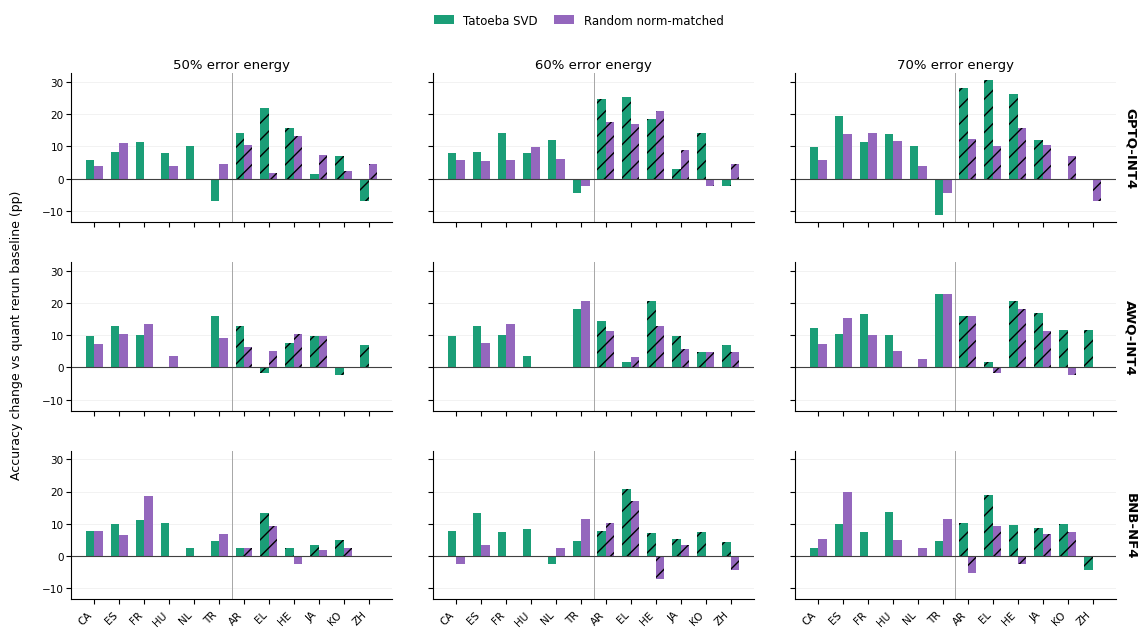

In [13]:
# Replace the original `for method in QUANT_METHODS:` per-language plotting
# block with this cell. SUMMARY_DF must already have been constructed.

n_method_rows = len(QUANT_METHODS)
n_threshold_cols = len(RECOVERY_ENERGY_THRESHOLDS)

fig, axes = plt.subplots(
    n_method_rows,
    n_threshold_cols,
    figsize=(11.8, 6.7),
    sharex=True,
    sharey=True,
    squeeze=False,
)

legend_handles = None
legend_labels = None

for method_row, method in enumerate(QUANT_METHODS):
    for threshold_col, threshold in enumerate(RECOVERY_ENERGY_THRESHOLDS):
        ax = axes[method_row, threshold_col]
        learned_values = []
        normmatched_values = []

        for language in TARGET_LANGUAGES:
            part = SUMMARY_DF[
                SUMMARY_DF.method.eq(method)
                & SUMMARY_DF.language.eq(language)
                & SUMMARY_DF.cohort.eq('all_selected')
                & SUMMARY_DF.energy_threshold.eq(threshold)
            ]
            learned_row = part[part.control.eq('tatoeba_svd')]
            normmatched_rows = part[
                part.control.eq('random_norm_matched')
            ]
            if (
                len(learned_row) != 1
                or len(normmatched_rows) != RANDOM_CONTROL_REPEATS
            ):
                raise RuntimeError(
                    f'Missing per-language result: '
                    f'{method}/{language}/{threshold}'
                )

            baseline = float(
                learned_row.rerun_baseline_accuracy.iloc[0]
            )
            learned_values.append(
                100
                * (
                    float(learned_row.patched_accuracy.iloc[0])
                    - baseline
                )
            )
            normmatched_values.append(
                100
                * (
                    float(normmatched_rows.patched_accuracy.mean())
                    - baseline
                )
            )

        x = np.arange(len(TARGET_LANGUAGES))
        width = 0.34
        for offset, values, label, color in [
            (-width / 2, learned_values, 'Tatoeba SVD', '#1B9E77'),
            (
                width / 2,
                normmatched_values,
                'Random norm-matched',
                '#9467BD',
            ),
        ]:
            bars = ax.bar(
                x + offset,
                values,
                width,
                label=label,
                color=color,
            )
            for bar, language in zip(bars, TARGET_LANGUAGES):
                if LANGUAGE_SCRIPT_GROUPS[language] == 'Non-Latin':
                    bar.set_hatch('//')

        # Threshold labels are column headers, not figure titles.
        if method_row == 0:
            ax.set_title(
                f'{int(round(threshold * 100))}% error energy',
                fontsize=9.5,
                pad=4,
            )

        if method_row == n_method_rows - 1:
            ax.set_xticks(
                x,
                [language.upper() for language in TARGET_LANGUAGES],
                rotation=45,
                ha='right',
                fontsize=7.5,
            )
        else:
            ax.tick_params(axis='x', labelbottom=False)

        ax.axvline(5.5, color='0.65', linewidth=0.7)
        ax.axhline(0, color='0.25', linewidth=0.8)
        ax.tick_params(axis='y', labelsize=7.5, pad=2)
        ax.grid(axis='y', alpha=0.18, linewidth=0.6)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()

    # Quantization method is shown once, vertically, at the right of each row.
    axes[method_row, -1].annotate(
        method,
        xy=(1.045, 0.5),
        xycoords='axes fraction',
        ha='center',
        va='center',
        rotation=270,
        fontsize=9.5,
        fontweight='bold',
        annotation_clip=False,
    )

fig.supylabel(
    'Accuracy change vs quant rerun baseline (pp)',
    x=0.018,
    fontsize=9,
)
fig.legend(
    legend_handles,
    legend_labels,
    loc='upper center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.995),
    frameon=False,
    fontsize=8.5,
    columnspacing=1.4,
    handlelength=1.7,
)
fig.subplots_adjust(
    left=0.07,
    right=0.955,
    top=0.89,
    bottom=0.105,
    wspace=0.13,
    hspace=0.27,
)

stem = OUTPUT_DIR / 'three_method_compact_per_language_recovery'
fig.savefig(
    stem.with_suffix('.png'),
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.03,
)
fig.savefig(
    stem.with_suffix('.pdf'),
    bbox_inches='tight',
    pad_inches=0.03,
)
plt.show()

In [14]:
stem

PosixPath('/root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/content_masked_mean_tokens/tatoeba_common_error_subspace_all_content_tokens_klar/three_method_compact_per_language_recovery')